<a href="https://colab.research.google.com/github/Krishanu2006/Crop_Disease_prediction/blob/main/01_PlantVillage_Dataset_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install datasets

In [6]:
from datasets import load_dataset

# Load the dataset using the available default configuration
dataset = load_dataset("mohanty/PlantVillage", "default")

README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

segmented_test.txt:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [7]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 22.51 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.


In [9]:
import os

dataset_root = "/content/PlantVillage-Dataset"

for root, dirs, files in os.walk(dataset_root):
    depth = root.replace(dataset_root, "").count(os.sep)

    if depth > 2:
        dirs[:] = []
        continue

    print(
        "  " * depth
        + os.path.basename(root)
        + f" ({len(files)} files)"
    )

PlantVillage-Dataset (9 files)
  data_distribution_for_SVM (2 files)
    test (0 files)
    train (0 files)
  utils (4 files)
  generated_for_paper (62 files)
  scripts (18 files)
  .git (6 files)
    hooks (14 files)
    info (1 files)
    objects (0 files)
    refs (0 files)
    logs (1 files)
    branches (0 files)
  raw (0 files)
    grayscale (0 files)
    color (0 files)
    segmented (0 files)
  leaf_grouping (4 files)
    leaf_maps (45 files)
    filtered_leafmaps (31 files)
  logs (15 files)


In [10]:
import os

for root, dirs, files in os.walk(dataset_root):
    class_dirs = [
        d for d in dirs
        if "___" in d
    ]

    if len(class_dirs) > 0:
        print("Potential dataset directory:", root)
        print("Number of class folders:", len(class_dirs))
        print("Example classes:", class_dirs[:5])
        print()

Potential dataset directory: /content/PlantVillage-Dataset/raw/grayscale
Number of class folders: 38
Example classes: ['Grape___Black_rot', 'Cherry_(including_sour)___Powdery_mildew', 'Apple___Cedar_apple_rust', 'Blueberry___healthy', 'Raspberry___healthy']

Potential dataset directory: /content/PlantVillage-Dataset/raw/color
Number of class folders: 38
Example classes: ['Grape___Black_rot', 'Cherry_(including_sour)___Powdery_mildew', 'Apple___Cedar_apple_rust', 'Blueberry___healthy', 'Raspberry___healthy']

Potential dataset directory: /content/PlantVillage-Dataset/raw/segmented
Number of class folders: 38
Example classes: ['Grape___Black_rot', 'Cherry_(including_sour)___Powdery_mildew', 'Apple___Cedar_apple_rust', 'Blueberry___healthy', 'Raspberry___healthy']



PLANTVILLAGE DATASET SUMMARY
Dataset directory: /content/PlantVillage-Dataset/raw/color
Number of classes: 38
Total images: 54305
Average images per class: 1429.08
Smallest class size: 152
Largest class size: 5507
Classes with zero images: []
Unexpected non-image files: 0

Five smallest classes:
                       Class  Image Count
            Potato___healthy          152
    Apple___Cedar_apple_rust          275
             Peach___healthy          360
         Raspberry___healthy          371
Tomato___Tomato_mosaic_virus          373

Five largest classes:
                                   Class  Image Count
Orange___Haunglongbing_(Citrus_greening)         5507
  Tomato___Tomato_Yellow_Leaf_Curl_Virus         5357
                       Soybean___healthy         5090
                  Peach___Bacterial_spot         2297
                 Tomato___Bacterial_spot         2127


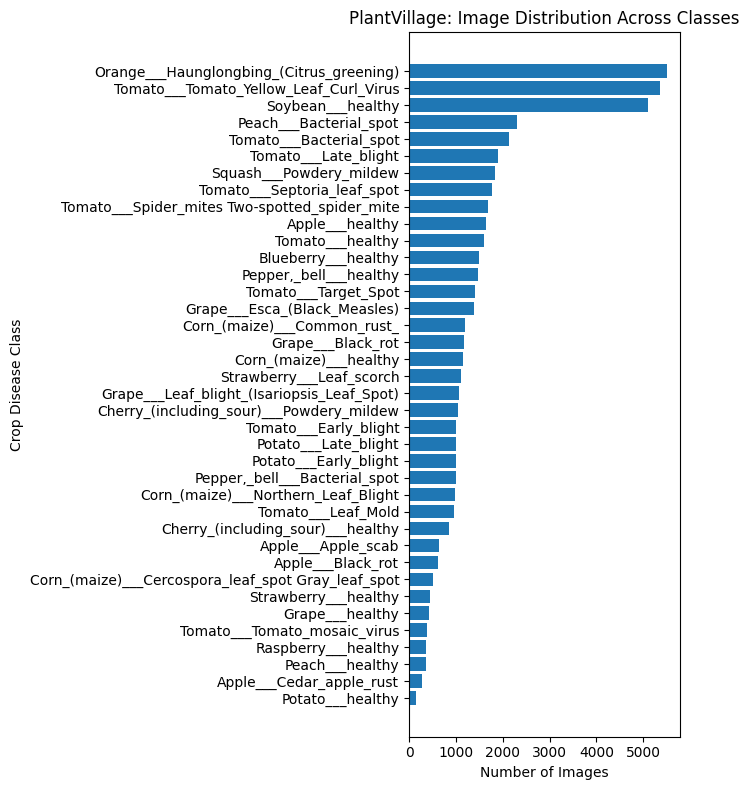

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

dataset_dir = "/content/PlantVillage-Dataset/raw/color"

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}
unexpected_files = []

for class_name in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    image_files = [
        filename
        for filename in os.listdir(class_path)
        if os.path.isfile(os.path.join(class_path, filename))
        and os.path.splitext(filename)[1].lower() in valid_extensions
    ]

    class_counts[class_name] = len(image_files)

    for filename in os.listdir(class_path):
        filepath = os.path.join(class_path, filename)

        if os.path.isfile(filepath):
            ext = os.path.splitext(filename)[1].lower()
            if ext not in valid_extensions:
                unexpected_files.append(filepath)

# Summary
total_images = sum(class_counts.values())

print("=" * 50)
print("PLANTVILLAGE DATASET SUMMARY")
print("=" * 50)
print("Dataset directory:", dataset_dir)
print("Number of classes:", len(class_counts))
print("Total images:", total_images)
print("Average images per class:", round(total_images / len(class_counts), 2))
print("Smallest class size:", min(class_counts.values()))
print("Largest class size:", max(class_counts.values()))
print("Classes with zero images:",
      [name for name, count in class_counts.items() if count == 0])
print("Unexpected non-image files:", len(unexpected_files))

# Create a table
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image Count"]
)

df = df.sort_values("Image Count", ascending=True).reset_index(drop=True)

print("\nFive smallest classes:")
print(df.head(5).to_string(index=False))

print("\nFive largest classes:")
print(df.tail(5).sort_values("Image Count", ascending=False).to_string(index=False))

# Visualize class distribution
plt.figure(figsize=(7, 8))
plt.barh(df["Class"], df["Image Count"])
plt.xlabel("Number of Images")
plt.ylabel("Crop Disease Class")
plt.title("PlantVillage: Image Distribution Across Classes")
plt.tight_layout()
plt.show()

In [12]:
import os

repo_dir = "/content/PlantVillage-Dataset"

print("Repository root:")
print(os.listdir(repo_dir))

print("\nPotential split and grouping files:")

for root, dirs, files in os.walk(repo_dir):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__"}
    ]

    for filename in files:
        lower_name = filename.lower()

        if any(
            keyword in lower_name
            for keyword in ["split", "leaf", "group", "manifest"]
        ):
            print(os.path.join(root, filename))

Streaming output truncated to the last 5000 lines.
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/1a9a2cbf-75f3-4dd9-93ef-3d3c58e97d06___GHLB2 Leaf 8666.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/07897854-c2ab-465b-8cf7-a134b6066a1c___GHLB Leaf 1.1 Day 6.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/d08bee32-4f76-4a08-9158-69fe55da2ddb___GHLB Leaf 23 Day 12.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/09590524-981f-4dc5-b6e3-5225a0c48019___GHLB2ES Leaf 140.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/a1f7a744-1d30-4343-992c-b1521d924094___GHLB2 Leaf 8563.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/af7021ea-5138-4b6f-9ee5-c05daf993791___GHLB2 Leaf 77.1.JPG
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_blight/16b43113-cc8c-4082-a88f-648b79036e49___GHLB_PS Leaf 23.4 Day 13.jpg
/content/PlantVillage-Dataset/raw/grayscale/Tomato___Late_bligh

In [13]:
import os

repo_dir = "/content/PlantVillage-Dataset"

print("Potential metadata files:\n")

for root, dirs, files in os.walk(repo_dir):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__"}
    ]

    for filename in files:
        if filename.lower().endswith(
            (".csv", ".json", ".jsonl", ".txt", ".parquet")
        ):
            print(os.path.join(root, filename))

Potential metadata files:

/content/PlantVillage-Dataset/leaf-map.json
/content/PlantVillage-Dataset/data_distribution_for_SVM/train_mapping.txt
/content/PlantVillage-Dataset/data_distribution_for_SVM/test_mapping.txt
/content/PlantVillage-Dataset/leaf_grouping/leaf-map.json
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Raspberry_Sheet1.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Tomato_Leaf Mold Fungus.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Citrus_Citrus Greening June.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Pepper_Bacterial Spot JR.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Strawberry_Scorch.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Cherry_Healthy.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Soy_Sheet1.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Potato_Early Blight Fungus.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Tomato_Bacterial Spot Bacteria.csv
/conte

In [14]:
!find /content/PlantVillage-Dataset -maxdepth 3 -type f \
  \( -iname "*split*" -o -iname "*train*" -o -iname "*test*" -o -iname "*leaf*" \) \
  | head -80

/content/PlantVillage-Dataset/data_distribution_for_SVM/train_mapping.txt
/content/PlantVillage-Dataset/data_distribution_for_SVM/test_mapping.txt
/content/PlantVillage-Dataset/leaf-map.json
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Tomato Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Tomato_Leaf Mold Fungus.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Peach Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Strawberry Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Cherry Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Blueberry Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Potato Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Citrus Leaf Counts.xlsx
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Tomato_Septoria Leaf Spot Fungus.csv
/content/PlantVillage-Dataset/leaf_grouping/leaf_maps/Grape Leaf Counts.xlsx
/conten

In [15]:
from pathlib import Path

repo_dir = Path("/content/PlantVillage-Dataset")

mapping_files = [
    repo_dir / "data_distribution_for_SVM" / "train_mapping.txt",
    repo_dir / "data_distribution_for_SVM" / "test_mapping.txt",
]

for filepath in mapping_files:
    print("\n" + "=" * 70)
    print(f"File: {filepath.name}")
    print("=" * 70)

    if not filepath.exists():
        print("File not found.")
        continue

    with filepath.open("r", encoding="utf-8") as f:
        lines = f.readlines()

    print("Total lines:", len(lines))
    print("\nFirst 15 lines:")

    for line in lines[:15]:
        print(repr(line.rstrip("\n")))


File: train_mapping.txt
Total lines: 8751

First 15 lines:
'raw/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/43942641-100d-409a-a349-99175f84c629___YLCV_NREC 2938.JPG\tSVM/train/35/791b93b5-1432-4ba7-bce2-0c9df61ff5f8.JPG'
'raw/color/Grape___Black_rot/e671f7da-5f56-4409-8239-e31500250709___FAM_B.Rot 0743.JPG\tSVM/train/11/267f87a9-6c00-45af-af0a-9d043bf6b44b.JPG'
'raw/color/Blueberry___healthy/1a779cff-baa3-4209-afc9-be30705607a5___RS_HL 4886.JPG\tSVM/train/4/3de3d494-d7b0-4d09-9dc0-927bd4796458.JPG'
'raw/color/Tomato___Bacterial_spot/367ef1cf-9ddd-40ba-9809-4652b3c2acd2___GCREC_Bact.Sp 2953.JPG\tSVM/train/28/338cf7c5-f144-4345-be27-488ef0f49e61.JPG'
'raw/color/Pepper,_bell___healthy/28cb1970-1ca2-452a-ace6-cd98f1aeb57c___JR_HL 8886.JPG\tSVM/train/19/3e435ccd-6061-4cc2-bb0a-31cbc9c2aa04.JPG'
'raw/color/Tomato___Late_blight/3bfcacdf-3d19-47c4-a52e-6d884dfc5e20___RS_Late.B 6651.JPG\tSVM/train/30/5a29d017-e63b-45d5-9009-2bb0d17106db.JPG'
'raw/color/Tomato___healthy/8934ec44-9624-4e9e-af5

In [16]:
import json
from pathlib import Path

json_path = Path("/content/PlantVillage-Dataset/leaf-map.json")

with json_path.open("r", encoding="utf-8") as f:
    leaf_map = json.load(f)

print("Python data type:", type(leaf_map).__name__)

if isinstance(leaf_map, dict):
    print("Number of top-level entries:", len(leaf_map))

    for i, (key, value) in enumerate(leaf_map.items()):
        print(f"\nEntry {i + 1}")
        print("Key:", repr(key))
        print("Value:", repr(value))

        if i == 4:
            break

elif isinstance(leaf_map, list):
    print("Number of entries:", len(leaf_map))

    for item in leaf_map[:5]:
        print(repr(item))

Python data type: dict
Number of top-level entries: 40328

Entry 1
Key: 'rutg._hl 3733'
Value: ['Peach___healthy:::54.0']

Entry 2
Key: 'com.g_fl 8310'
Value: ['Tomato___Target_Spot:::243.0']

Entry 3
Key: 'rs_early.b 7557'
Value: ['Potato___Early_blight:::115.0']

Entry 4
Key: 'rs_early.b 7554'
Value: ['Potato___Early_blight:::115.0']

Entry 5
Key: 'uf.citrus_hlb_lab 1658'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']


In [17]:
import pandas as pd
from IPython.display import display

csv_path = (
    "/content/PlantVillage-Dataset/leaf_grouping/"
    "filtered_leafmaps/Potato___healthy.csv"
)

df_leaf = pd.read_csv(csv_path)

print("Shape:", df_leaf.shape)
print("\nColumn names:")
print(df_leaf.columns.tolist())

print("\nFirst 10 rows:")
display(df_leaf.head(10))

print("\nData types:")
print(df_leaf.dtypes)

Shape: (152, 2)

Column names:
['File Name', 'Leaf #']

First 10 rows:


,File Name,Leaf #
0,RS_HL 1735.JPG,1.0
1,RS_HL 1736.JPG,1.0
2,RS_HL 1738.JPG,1.0
3,RS_HL 1740.JPG,1.0
4,RS_HL 1745.JPG,2.0
5,RS_HL 1746.JPG,2.0
6,RS_HL 1747.JPG,2.0
7,RS_HL 1748.JPG,2.0
8,RS_HL 1750.JPG,3.0
9,RS_HL 1751.JPG,3.0



Data types:
File Name     object
Leaf #       float64
dtype: object


In [18]:
import os
import json
import re
from collections import Counter, defaultdict

repo_dir = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo_dir, "raw", "color")
json_path = os.path.join(repo_dir, "leaf-map.json")

with open(json_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)


def normalize_name(name):
    """Normalize a filename suffix for matching."""
    name = os.path.basename(name)
    name = os.path.splitext(name)[0]
    name = name.strip().lower()
    name = re.sub(r"\s+", " ", name)
    return name


# Index the JSON by normalized filename key.
json_index = defaultdict(list)

for key, values in leaf_map.items():
    normalized_key = normalize_name(key)

    for value in values:
        if ":::" in value:
            class_name, leaf_id = value.rsplit(":::", 1)

            json_index[(
                class_name,
                normalized_key
            )].append(leaf_id)


# Examine all color images.
total_images = 0
matched_images = 0
unmatched_images = []
group_counts = Counter()
class_image_counts = Counter()
class_matched_counts = Counter()

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        filepath = os.path.join(class_path, filename)

        if not os.path.isfile(filepath):
            continue

        if os.path.splitext(filename)[1].lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        total_images += 1
        class_image_counts[class_name] += 1

        # Original filenames generally contain a UUID followed by ___.
        suffix = filename.split("___", 1)[-1]
        normalized_suffix = normalize_name(suffix)

        matches = json_index.get(
            (class_name, normalized_suffix), []
        )

        if matches:
            matched_images += 1
            class_matched_counts[class_name] += 1

            # Use class + leaf ID as the grouping identifier.
            for leaf_id in set(matches):
                group_counts[(class_name, leaf_id)] += 1
        else:
            unmatched_images.append(
                (class_name, filename)
            )


print("=" * 55)
print("LEAF METADATA COVERAGE")
print("=" * 55)
print("Total color images:", total_images)
print("Images matched to leaf metadata:", matched_images)
print("Images without a match:", len(unmatched_images))
print(
    "Metadata coverage:",
    f"{100 * matched_images / total_images:.2f}%"
)

print("\nNumber of distinct class/leaf groups:", len(group_counts))

print("\nGroups containing multiple image records:")
multi_image_groups = sum(
    count > 1 for count in group_counts.values()
)
print(multi_image_groups)

print("\nClasses with the lowest metadata coverage:")

coverage = []

for class_name, total in class_image_counts.items():
    matched = class_matched_counts[class_name]
    coverage.append((
        class_name,
        total,
        matched,
        round(100 * matched / total, 2)
    ))

coverage.sort(key=lambda x: x[3])

for row in coverage[:10]:
    print(row)

print("\nExamples of unmatched images:")
for item in unmatched_images[:10]:
    print(item)

LEAF METADATA COVERAGE
Total color images: 54305
Images matched to leaf metadata: 20284
Images without a match: 34021
Metadata coverage: 37.35%

Number of distinct class/leaf groups: 3524

Groups containing multiple image records:
3520

Classes with the lowest metadata coverage:
('Apple___Black_rot', 621, 0, 0.0)
('Apple___Cedar_apple_rust', 275, 0, 0.0)
('Cherry_(including_sour)___Powdery_mildew', 1052, 0, 0.0)
('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 513, 0, 0.0)
('Corn_(maize)___Common_rust_', 1192, 0, 0.0)
('Corn_(maize)___Northern_Leaf_Blight', 985, 0, 0.0)
('Corn_(maize)___healthy', 1162, 0, 0.0)
('Grape___Black_rot', 1180, 0, 0.0)
('Grape___Esca_(Black_Measles)', 1383, 0, 0.0)
('Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 1076, 0, 0.0)

Examples of unmatched images:
('Apple___Black_rot', 'a8ce9225-ca25-41ba-8c19-4d80ffcb4c93___JR_FrgE.S 8570.JPG')
('Apple___Black_rot', 'b970ac93-7f26-41ae-a5ed-fc509e209c12___JR_FrgE.S 8808.JPG')
('Apple___Black_rot', 'c8269293-ae8

In [19]:
import os
import json
import re
from collections import Counter, defaultdict

repo_dir = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo_dir, "raw", "color")
json_path = os.path.join(repo_dir, "leaf-map.json")

with open(json_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)


def normalize(text):
    text = os.path.basename(text)
    text = os.path.splitext(text)[0]
    text = text.strip().lower()
    text = re.sub(r"\s+", " ", text)
    return text


# Examine the class labels represented in the JSON values.
json_class_counts = Counter()
json_key_index = defaultdict(list)

for key, values in leaf_map.items():
    normalized_key = normalize(key)
    json_key_index[normalized_key].append((key, values))

    for value in values:
        if ":::" in value:
            class_name, leaf_id = value.rsplit(":::", 1)
            json_class_counts[class_name] += 1

print("Number of JSON keys:", len(leaf_map))
print("Classes represented in JSON:", len(json_class_counts))

print("\nImage-record counts by class in JSON:")
for class_name, count in json_class_counts.most_common():
    print(f"{class_name}: {count}")


# Check whether image suffixes match JSON keys without requiring class equality.
total_images = 0
filename_matches = 0
class_and_filename_matches = 0
filename_only_examples = []

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        filepath = os.path.join(class_path, filename)

        if not os.path.isfile(filepath):
            continue

        if os.path.splitext(filename)[1].lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        total_images += 1

        suffix = filename.split("___", 1)[-1]
        normalized_suffix = normalize(suffix)

        if normalized_suffix in json_key_index:
            filename_matches += 1

            values = [
                value
                for _, value_list in json_key_index[normalized_suffix]
                for value in value_list
            ]

            if any(
                value.startswith(class_name + ":::")
                for value in values
            ):
                class_and_filename_matches += 1
            elif len(filename_only_examples) < 10:
                filename_only_examples.append(
                    (class_name, filename, values)
                )


print("\n" + "=" * 55)
print("FILENAME MATCH DIAGNOSTIC")
print("=" * 55)
print("Total images:", total_images)
print("Filename-only matches:", filename_matches)
print("Filename + class matches:", class_and_filename_matches)

print("\nFilename matches with different class labels:")
for example in filename_only_examples:
    print(example)


Number of JSON keys: 40328
Classes represented in JSON: 31

Image-record counts by class in JSON:
Orange___Haunglongbing_(Citrus_greening): 5508
Soybean___healthy: 5091
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 2740
Peach___Bacterial_spot: 2297
Tomato___Bacterial_spot: 2128
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Apple___healthy: 1639
Blueberry___healthy: 1503
Pepper,_bell___healthy: 1476
Tomato___Target_Spot: 1404
Grape___Esca_(Black_Measles): 1384
Grape___Black_rot: 1180
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Cherry_(including_sour)___Powdery_mildew: 1052
Potato___Early_blight: 1000
Tomato___Early_blight: 1000
Tomato___healthy: 1000
Tomato___Septoria_leaf_spot: 1000
Potato___Late_blight: 1000
Pepper,_bell___Bacterial_spot: 997
Tomato___Leaf_Mold: 952
Tomato___Late_blight: 920
Cherry_(including_sour)___healthy: 854
Strawberry___Leaf_scorch: 776
Apple___Apple_scab: 630
Apple_Frogeye Spot: 621
Strawberry___healthy: 456
Raspberry___healthy: 371
Peach___healthy: 361
Ap

In [20]:
import os
import hashlib
from collections import defaultdict

dataset_dir = "/content/PlantVillage-Dataset/raw/color"

hash_to_images = defaultdict(list)
image_count = 0

for class_name in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        filepath = os.path.join(class_path, filename)

        if not os.path.isfile(filepath):
            continue

        if os.path.splitext(filename)[1].lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        image_count += 1

        with open(filepath, "rb") as f:
            file_hash = hashlib.sha256(f.read()).hexdigest()

        hash_to_images[file_hash].append(filepath)

duplicate_groups = {
    h: paths
    for h, paths in hash_to_images.items()
    if len(paths) > 1
}

duplicate_file_count = sum(
    len(paths) for paths in duplicate_groups.values()
)

print("Images inspected:", image_count)
print("Unique file hashes:", len(hash_to_images))
print("Exact duplicate groups:", len(duplicate_groups))
print("Images belonging to duplicate groups:", duplicate_file_count)

print("\nExample duplicate groups:")

for paths in list(duplicate_groups.values())[:5]:
    for path in paths:
        print(path)
    print()

Images inspected: 54305
Unique file hashes: 54284
Exact duplicate groups: 21
Images belonging to duplicate groups: 42

Example duplicate groups:
/content/PlantVillage-Dataset/raw/color/Apple___healthy/dc18b924-f172-445d-8fed-61445d437aaa___RS_HL 6270.JPG
/content/PlantVillage-Dataset/raw/color/Apple___healthy/ced4e27a-5eff-4190-a33a-cdc3d84c811e___RS_HL 6270.JPG

/content/PlantVillage-Dataset/raw/color/Apple___healthy/13298d36-4425-437d-ae8e-c7d70e200084___RS_HL 6271.JPG
/content/PlantVillage-Dataset/raw/color/Apple___healthy/11beda66-01e9-4bfd-be37-c0f8646d1478___RS_HL 6271.JPG

/content/PlantVillage-Dataset/raw/color/Apple___healthy/9b75de13-d4b0-4b3f-988c-3e9926eef957___RS_HL 6273.JPG
/content/PlantVillage-Dataset/raw/color/Apple___healthy/5192db55-4aa7-421c-92d4-c2dac79e7379___RS_HL 6273.JPG

/content/PlantVillage-Dataset/raw/color/Apple___healthy/fdbfa6f7-f887-442d-8df1-1f0cf839fc4d___RS_HL 6274.JPG
/content/PlantVillage-Dataset/raw/color/Apple___healthy/f2cda910-55c7-46d7-b1a2-9a

In [21]:
import os

repo = "/content/PlantVillage-Dataset"

files_to_check = [
    "README.md",
    "README_HF.md",
    "data_distribution_for_SVM/train_mapping.txt",
    "data_distribution_for_SVM/test_mapping.txt",
    "leaf-map.json",
    "leaf_grouping/leaf-map.json",
    "leaf_grouping/filtered_leafmaps/Potato___healthy.csv",
]

for relative_path in files_to_check:
    path = os.path.join(repo, relative_path)

    print(f"\n{'=' * 80}")
    print(f"FILE: {relative_path}")

    if not os.path.isfile(path):
        print("Not found")
        continue

    print(f"Size: {os.path.getsize(path):,} bytes")

    try:
        with open(path, "r", encoding="utf-8") as f:
            for line_number, line in enumerate(f):
                if line_number >= 5:
                    break
                print(line.rstrip()[:300])
    except UnicodeDecodeError:
        print("Not a plain UTF-8 text file; inspect separately.")


FILE: README.md
Size: 3,887 bytes
# PlantVillage Dataset

[![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-Dataset-blue)](https://huggingface.co/datasets/mohanty/PlantVillage)
[![Paper](https://img.shields.io/badge/Paper-Read-green)](https://www.frontiersin.org/journals/plant-science/articles/10.3389/fpls.2016.01419/full)


FILE: README_HF.md
Size: 6,471 bytes
---
language:
- en
license: cc-by-sa-3.0
task_categories:

FILE: data_distribution_for_SVM/train_mapping.txt
Size: 1,303,399 bytes
raw/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/43942641-100d-409a-a349-99175f84c629___YLCV_NREC 2938.JPG	SVM/train/35/791b93b5-1432-4ba7-bce2-0c9df61ff5f8.JPG
raw/color/Grape___Black_rot/e671f7da-5f56-4409-8239-e31500250709___FAM_B.Rot 0743.JPG	SVM/train/11/267f87a9-6c00-45af-af0a-9d043bf6b44b.JPG
raw/color/Blueberry___healthy/1a779cff-baa3-4209-afc9-be30705607a5___RS_HL 4886.JPG	SVM/train/4/3de3d494-d7b0-4d09-9dc0-927bd4796458.JPG
raw/color/Tomato___Bacterial_spot/367ef1

In [22]:
import os
import json
import re
from collections import defaultdict, Counter

repo = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo, "raw", "color")
leaf_map_path = os.path.join(repo, "leaf_grouping", "leaf-map.json")

# Load leaf metadata
with open(leaf_map_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

def normalize(text):
    text = text.replace("\\_", "_").strip().lower()
    return re.sub(r"\s+", " ", text)

normalized_leaf_map = {
    normalize(key): value for key, value in leaf_map.items()
}

matched_images = []
unmatched_images = []
class_mismatches = []
leaf_groups = defaultdict(list)
class_counts = Counter()

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if os.path.splitext(filename)[1].lower() not in valid_extensions:
            continue

        class_counts[class_name] += 1

        # Extract source identifier after UUID___
        base = os.path.splitext(filename)[0]
        source_id = (
            base.split("___", 1)[1].strip()
            if "___" in base else base.strip()
        )
        normalized_id = normalize(source_id)

        records = normalized_leaf_map.get(normalized_id)

        if not records:
            unmatched_images.append((class_name, filename))
            continue

        # The map stores entries such as ClassName:::54.0
        record = records[0]
        try:
            mapped_class, leaf_number = record.rsplit(":::", 1)
        except ValueError:
            unmatched_images.append((class_name, filename))
            continue

        if mapped_class != class_name:
            class_mismatches.append(
                (filename, class_name, mapped_class)
            )
            continue

        matched_images.append((class_name, filename))
        group_id = (class_name, leaf_number)
        leaf_groups[group_id].append(filename)

multi_image_groups = {
    group: filenames
    for group, filenames in leaf_groups.items()
    if len(filenames) > 1
}

print("========== LEAF-MAP VALIDATION ==========")
print("Total images:", sum(class_counts.values()))
print("Images matched to leaf metadata:", len(matched_images))
print("Images without a usable mapping:", len(unmatched_images))
print("Class-label mismatches:", len(class_mismatches))
print("Distinct mapped leaf groups:", len(leaf_groups))
print("Groups containing multiple images:", len(multi_image_groups))

print("\n========== EXAMPLES OF MULTI-IMAGE GROUPS ==========")
for group, filenames in list(multi_image_groups.items())[:10]:
    print(f"{group}: {len(filenames)} images")
    for filename in filenames[:5]:
        print("  ", filename)

print("\n========== UNMATCHED IMAGES BY CLASS ==========")
unmatched_by_class = Counter(cls for cls, _ in unmatched_images)
for cls, count in unmatched_by_class.most_common():
    print(f"{cls}: {count}")

========== LEAF-MAP VALIDATION ==========
Total images: 54305
Images matched to leaf metadata: 38291
Images without a usable mapping: 13194
Class-label mismatches: 2820
Distinct mapped leaf groups: 7215
Groups containing multiple images: 7185

========== EXAMPLES OF MULTI-IMAGE GROUPS ==========
('Apple___Apple_scab', '36.0'): 5 images
   1a21aabb-6f74-4644-8d9e-a517568b7e9c___FREC_Scab 3095.JPG
   461eeeb9-5bf1-4c0a-a7dd-6967917b4537___FREC_Scab 3098.JPG
   5eb564a6-cd74-4c90-95d9-611a6301369d___FREC_Scab 3099.JPG
   6105e3bd-339c-47bd-9764-4ba9b7059a6b___FREC_Scab 3096.JPG
   30111fee-0c22-4ca4-aeb4-ac14a9a5d651___FREC_Scab 3097.JPG
('Apple___Apple_scab', '28.0'): 4 images
   0261a6e4-21f8-481a-8827-b674e6955644___FREC_Scab 3055.JPG
   a0fd13e3-e36c-4386-beb2-ec6a587bfd70___FREC_Scab 3053.JPG
   895252c3-5047-4e87-8e13-2cdd765f3e0a___FREC_Scab 3056.JPG
   99e03a3c-c68f-4648-af09-877c57d6b115___FREC_Scab 3054.JPG
('Apple___Apple_scab', '78.0'): 8 images
   d1745979-75a6-4b00-a544-cf5b

In [23]:
import os
import json
import re
from collections import defaultdict, Counter

repo = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo, "raw", "color")
map_path = os.path.join(repo, "leaf_grouping", "leaf-map.json")

with open(map_path, "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

def normalize(text):
    text = text.replace("\\_", "_").strip().lower()
    return re.sub(r"\s+", " ", text)

# Preserve every original key so that normalization collisions are visible.
normalized_keys = defaultdict(list)

for original_key, records in leaf_map.items():
    normalized_keys[normalize(original_key)].append(
        (original_key, records)
    )

collisions = {
    key: entries
    for key, entries in normalized_keys.items()
    if len(entries) > 1
}

print("Original leaf-map keys:", len(leaf_map))
print("Distinct normalized keys:", len(normalized_keys))
print("Normalized-key collisions:", len(collisions))

print("\n========== COLLISION EXAMPLES ==========")
for key, entries in list(collisions.items())[:10]:
    print("\nNormalized key:", repr(key))
    for original_key, records in entries:
        print("  Original:", repr(original_key), "Records:", records)

# Examine image-to-map matches without assuming the map is correct.
mismatch_examples = []
match_counts = Counter()
class_pairs = Counter()

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if os.path.splitext(filename)[1].lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        base = os.path.splitext(filename)[0]
        source_id = base.split("___", 1)[1].strip() if "___" in base else base
        key = normalize(source_id)

        entries = normalized_keys.get(key)

        if not entries:
            match_counts["unmatched"] += 1
            continue

        match_counts["matched_key"] += 1

        # Inspect every entry for this normalized key.
        mapped_classes = set()

        for original_key, records in entries:
            for record in records:
                try:
                    mapped_class, leaf_number = record.rsplit(":::", 1)
                    mapped_classes.add(mapped_class)
                    if mapped_class != class_name:
                        class_pairs[(class_name, mapped_class)] += 1
                        if len(mismatch_examples) < 20:
                            mismatch_examples.append({
                                "folder_class": class_name,
                                "filename": filename,
                                "map_key": original_key,
                                "mapped_class": mapped_class,
                                "leaf_number": leaf_number
                            })
                except ValueError:
                    match_counts["malformed_record"] += 1

        if len(mapped_classes) > 1:
            match_counts["keys_with_multiple_mapped_classes"] += 1

print("\n========== MATCH SUMMARY ==========")
for name, count in match_counts.items():
    print(f"{name}: {count}")

print("\n========== MOST COMMON CLASS PAIRS ==========")
for (folder_class, mapped_class), count in class_pairs.most_common(15):
    print(f"Folder: {folder_class} | Map: {mapped_class} | Records: {count}")

print("\n========== MISMATCH EXAMPLES ==========")
for item in mismatch_examples:
    print(item)

Original leaf-map keys: 40328
Distinct normalized keys: 40328
Normalized-key collisions: 0

========== COLLISION EXAMPLES ==========

========== MATCH SUMMARY ==========
matched_key: 41111
keys_with_multiple_mapped_classes: 4370
unmatched: 13194

========== MOST COMMON CLASS PAIRS ==========
Folder: Apple___healthy | Map: Soybean___healthy | Records: 984
Folder: Soybean___healthy | Map: Apple___healthy | Records: 977
Folder: Apple___Black_rot | Map: Apple_Frogeye Spot | Records: 621
Folder: Soybean___healthy | Map: Blueberry___healthy | Records: 608
Folder: Blueberry___healthy | Map: Soybean___healthy | Records: 607
Folder: Blueberry___healthy | Map: Tomato___healthy | Records: 321
Folder: Tomato___healthy | Map: Blueberry___healthy | Records: 321
Folder: Soybean___healthy | Map: Strawberry___healthy | Records: 207
Folder: Strawberry___healthy | Map: Soybean___healthy | Records: 207
Folder: Potato___healthy | Map: Strawberry___healthy | Records: 43
Folder: Strawberry___healthy | Map: P

In [24]:
import os
import glob
import pandas as pd
from collections import defaultdict, Counter

repo = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo, "raw", "color")
csv_dir = os.path.join(repo, "leaf_grouping", "filtered_leafmaps")

# Build an index of source filenames for every image.
images_by_class = defaultdict(dict)

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)
    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        # CSVs generally use the original filename without the UUID prefix.
        source_name = (
            filename.split("___", 1)[1]
            if "___" in filename else filename
        )
        images_by_class[class_name][source_name.strip().lower()] = filename

csv_files = glob.glob(os.path.join(csv_dir, "*.csv"))

print("Class-specific CSV files:", len(csv_files))

total_images = sum(len(files) for files in images_by_class.values())
mapped_images = 0
mapped_groups = 0
multi_image_groups = 0

print("\nCoverage by class:")

for csv_path in sorted(csv_files):
    class_name = os.path.splitext(os.path.basename(csv_path))[0]

    if class_name not in images_by_class:
        print(f"{class_name}: no matching image folder")
        continue

    df = pd.read_csv(csv_path)

    if not {"File Name", "Leaf #"}.issubset(df.columns):
        print(f"{class_name}: unexpected columns {list(df.columns)}")
        continue

    available = images_by_class[class_name]
    matched_names = set()
    groups = defaultdict(list)

    for _, row in df.iterrows():
        filename = str(row["File Name"]).strip().lower()
        leaf_id = str(row["Leaf #"]).strip()

        if filename in available:
            matched_names.add(filename)
            groups[leaf_id].append(filename)

    mapped_images += len(matched_names)
    mapped_groups += len(groups)
    multi_image_groups += sum(
        len(names) > 1 for names in groups.values()
    )

    print(
        f"{class_name}: "
        f"{len(matched_names)}/{len(available)} images mapped; "
        f"{len(groups)} leaf groups; "
        f"{sum(len(names) > 1 for names in groups.values())} "
        f"groups with multiple images"
    )

print("\n========== TOTALS ==========")
print("Total color images:", total_images)
print("Images covered by class-specific CSVs:", mapped_images)
print(f"Coverage: {mapped_images / total_images:.2%}")
print("Leaf groups across CSVs:", mapped_groups)
print("Groups containing multiple images:", multi_image_groups)

Class-specific CSV files: 31

Coverage by class:
Apple_Frogeye Spot: no matching image folder
Apple___Apple_scab: 630/630 images mapped; 108 leaf groups; 107 groups with multiple images
Apple___Cedar_apple_rust: 275/275 images mapped; 69 leaf groups; 69 groups with multiple images
Apple___healthy: 1638/1638 images mapped; 257 leaf groups; 256 groups with multiple images
Blueberry___healthy: 1502/1502 images mapped; 160 leaf groups; 160 groups with multiple images
Cherry_(including_sour)___Powdery_mildew: 1052/1052 images mapped; 65 leaf groups; 58 groups with multiple images
Cherry_(including_sour)___healthy: 854/854 images mapped; 107 leaf groups; 107 groups with multiple images
Grape___Black_rot: 1180/1180 images mapped; 295 leaf groups; 295 groups with multiple images
Grape___Esca_(Black_Measles): 1383/1383 images mapped; 346 leaf groups; 346 groups with multiple images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076/1076 images mapped; 269 leaf groups; 269 groups with multiple ima

In [25]:
import os
import glob
import pandas as pd
from collections import Counter, defaultdict

repo = "/content/PlantVillage-Dataset"
color_dir = os.path.join(repo, "raw", "color")
csv_dir = os.path.join(repo, "leaf_grouping", "filtered_leafmaps")

extensions = Counter()
all_images = defaultdict(dict)

for class_name in sorted(os.listdir(color_dir)):
    class_path = os.path.join(color_dir, class_name)
    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        path = os.path.join(class_path, filename)

        if not os.path.isfile(path):
            continue

        ext = os.path.splitext(filename)[1].lower()
        extensions[ext] += 1

        if ext not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            continue

        source_name = (
            filename.split("___", 1)[1]
            if "___" in filename else filename
        ).strip().lower()

        all_images[class_name][source_name] = filename

print("========== FILE EXTENSIONS ==========")
for ext, count in extensions.most_common():
    print(f"{ext or '[no extension]'}: {count}")

print("\n========== CSV COVERAGE GAPS ==========")

for csv_path in sorted(glob.glob(os.path.join(csv_dir, "*.csv"))):
    class_name = os.path.splitext(os.path.basename(csv_path))[0]

    if class_name not in all_images:
        continue

    df = pd.read_csv(csv_path)

    if not {"File Name", "Leaf #"}.issubset(df.columns):
        continue

    csv_names = set(
        df["File Name"].dropna().astype(str).str.strip().str.lower()
    )
    image_names = set(all_images[class_name])

    missing = sorted(image_names - csv_names)
    csv_only = sorted(csv_names - image_names)

    if missing or csv_only:
        print(f"\n{class_name}")
        print(f"  Images absent from CSV: {len(missing)}")
        print(f"  CSV names absent from image folder: {len(csv_only)}")
        print("  Missing-image examples:", missing[:5])
        print("  CSV-only examples:", csv_only[:5])

========== FILE EXTENSIONS ==========
.jpg: 54303
.png: 1
.jpeg: 1

========== CSV COVERAGE GAPS ==========

Apple___Cedar_apple_rust
  Images absent from CSV: 0
  CSV names absent from image folder: 1
  Missing-image examples: []
  CSV-only examples: ['frec_c.rust 9996.jpg']

Apple___healthy
  Images absent from CSV: 0
  CSV names absent from image folder: 1
  Missing-image examples: []
  CSV-only examples: ['rs_hl 7902.jpg']

Blueberry___healthy
  Images absent from CSV: 0
  CSV names absent from image folder: 1
  Missing-image examples: []
  CSV-only examples: ['rs_hl 5494.jpg']

Grape___Esca_(Black_Measles)
  Images absent from CSV: 0
  CSV names absent from image folder: 1
  Missing-image examples: []
  CSV-only examples: ['fam_b.msls 4430.jpg']

Orange___Haunglongbing_(Citrus_greening)
  Images absent from CSV: 0
  CSV names absent from image folder: 1
  Missing-image examples: []
  CSV-only examples: ['crec_hlb 7486.jpg']

Peach___healthy
  Images absent from CSV: 0
  CSV names 

In [26]:
import os
import hashlib
import pandas as pd
from collections import defaultdict

# Dataset paths
DATASET_DIR = "/content/PlantVillage-Dataset/raw/color"
OUTPUT_DIR = "/content/plant_disease_preprocessing"

os.makedirs(OUTPUT_DIR, exist_ok=True)

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
hash_to_paths = defaultdict(list)
class_counts = defaultdict(int)

# Scan all class folders
for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):
        image_path = os.path.join(class_path, filename)

        if not os.path.isfile(image_path):
            continue

        extension = os.path.splitext(filename)[1].lower()

        if extension not in VALID_EXTENSIONS:
            continue

        # Calculate the exact file hash
        sha256 = hashlib.sha256()

        with open(image_path, "rb") as image_file:
            for chunk in iter(lambda: image_file.read(1024 * 1024), b""):
                sha256.update(chunk)

        file_hash = sha256.hexdigest()

        records.append({
            "image_path": image_path,
            "filename": filename,
            "class_label": class_name,
            "extension": extension,
            "sha256": file_hash
        })

        hash_to_paths[file_hash].append(image_path)
        class_counts[class_name] += 1

# Build and save the inventory
inventory = pd.DataFrame(records)

inventory_path = os.path.join(
    OUTPUT_DIR, "image_inventory.csv"
)

inventory.to_csv(inventory_path, index=False)

# Find exact duplicates
duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_to_paths.items()
    if len(paths) > 1
}

duplicate_rows = []

for file_hash, paths in duplicate_groups.items():
    for path in paths:
        duplicate_rows.append({
            "sha256": file_hash,
            "image_path": path,
            "class_label": os.path.basename(
                os.path.dirname(path)
            ),
            "number_of_copies": len(paths)
        })

duplicates_df = pd.DataFrame(duplicate_rows)

duplicates_path = os.path.join(
    OUTPUT_DIR, "exact_duplicates.csv"
)

duplicates_df.to_csv(duplicates_path, index=False)

# Report results
print("========== IMAGE INVENTORY ==========")
print("Total images:", len(inventory))
print("Number of classes:", inventory["class_label"].nunique())
print("Unique SHA-256 hashes:", inventory["sha256"].nunique())
print("Exact duplicate groups:", len(duplicate_groups))
print("Files belonging to duplicate groups:", len(duplicates_df))
print(
    "Extra copies beyond one per group:",
    sum(len(paths) - 1 for paths in duplicate_groups.values())
)

print("\n========== CLASS COUNTS ==========")
print(
    inventory["class_label"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n========== FILES SAVED ==========")
print(inventory_path)
print(duplicates_path)

========== IMAGE INVENTORY ==========
Total images: 54305
Number of classes: 38
Unique SHA-256 hashes: 54284
Exact duplicate groups: 21
Files belonging to duplicate groups: 42
Extra copies beyond one per group: 21

========== CLASS COUNTS ==========
class_label
Apple___Apple_scab                                     630
Apple___Black_rot                                      621
Apple___Cedar_apple_rust                               275
Apple___healthy                                       1645
Blueberry___healthy                                   1502
Cherry_(including_sour)___Powdery_mildew              1052
Cherry_(including_sour)___healthy                      854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
Corn_(maize)___Common_rust_                           1192
Corn_(maize)___Northern_Leaf_Blight                    985
Corn_(maize)___healthy                                1162
Grape___Black_rot                                     1180
Grape___Esca_(Black_Measles)  

In [27]:
import pandas as pd
import os

inventory_path = (
    "/content/plant_disease_preprocessing/image_inventory.csv"
)

inventory = pd.read_csv(inventory_path)

print("Inventory rows:", len(inventory))
print("Distinct image paths:", inventory["image_path"].nunique())
print("Distinct classes:", inventory["class_label"].nunique())
print("Missing image paths:", (~inventory["image_path"].apply(os.path.isfile)).sum())
print("Missing hashes:", inventory["sha256"].isna().sum())
print("Missing class labels:", inventory["class_label"].isna().sum())

Inventory rows: 54305
Distinct image paths: 54305
Distinct classes: 38
Missing image paths: 0
Missing hashes: 0
Missing class labels: 0


In [28]:
import pandas as pd

inventory_path = (
    "/content/plant_disease_preprocessing/image_inventory.csv"
)

inventory = pd.read_csv(inventory_path)

# Find groups of identical image content
duplicate_summary = (
    inventory.groupby("sha256")
    .agg(
        copies=("image_path", "count"),
        classes=("class_label", "nunique"),
        paths=("image_path", list),
        labels=("class_label", list)
    )
    .query("copies > 1")
    .reset_index()
)

print("Exact duplicate groups:", len(duplicate_summary))
print(
    "Groups with conflicting labels:",
    (duplicate_summary["classes"] > 1).sum()
)

for _, row in duplicate_summary.iterrows():
    print(f"\nCopies: {row['copies']}")
    print(f"Labels: {row['labels']}")
    for path in row["paths"]:
        print(" ", path)

Exact duplicate groups: 21
Groups with conflicting labels: 0

Copies: 2
Labels: ['Tomato___healthy', 'Tomato___healthy']
  /content/PlantVillage-Dataset/raw/color/Tomato___healthy/488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL Leaf 434.JPG
  /content/PlantVillage-Dataset/raw/color/Tomato___healthy/a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL Leaf 434.JPG

Copies: 2
Labels: ['Apple___healthy', 'Apple___healthy']
  /content/PlantVillage-Dataset/raw/color/Apple___healthy/f2cda910-55c7-46d7-b1a2-9a3bb9792148___RS_HL 6274.JPG
  /content/PlantVillage-Dataset/raw/color/Apple___healthy/fdbfa6f7-f887-442d-8df1-1f0cf839fc4d___RS_HL 6274.JPG

Copies: 2
Labels: ['Tomato___healthy', 'Tomato___healthy']
  /content/PlantVillage-Dataset/raw/color/Tomato___healthy/068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf 466.1.JPG
  /content/PlantVillage-Dataset/raw/color/Tomato___healthy/34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG

Copies: 2
Labels: ['Tomato___Late_blight', 'Tomato___Late_blight

In [29]:
import os
import pandas as pd

BASE_DIR = "/content/PlantVillage-Dataset/leaf_grouping"

CSV_DIRS = [
    os.path.join(BASE_DIR, "filtered_leafmaps"),
    os.path.join(BASE_DIR, "leaf_maps"),
]

for csv_dir in CSV_DIRS:
    print(f"\n{'=' * 70}")
    print("DIRECTORY:", csv_dir)

    if not os.path.isdir(csv_dir):
        print("Directory not found.")
        continue

    csv_files = [
        f for f in os.listdir(csv_dir)
        if f.lower().endswith(".csv")
    ]

    print("Number of CSV files:", len(csv_files))

    for filename in sorted(csv_files)[:8]:
        path = os.path.join(csv_dir, filename)

        try:
            df = pd.read_csv(path)

            print(f"\nFile: {filename}")
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.head(3).to_string(index=False))

        except Exception as e:
            print(f"Could not read {filename}: {e}")


DIRECTORY: /content/PlantVillage-Dataset/leaf_grouping/filtered_leafmaps
Number of CSV files: 31

File: Apple_Frogeye Spot.csv
Shape: (621, 2)
Columns: ['File Name', 'Leaf #']
         File Name  Leaf #
JR_FrgE.S 2729.JPG     1.0
JR_FrgE.S 2730.JPG     1.0
JR_FrgE.S 2731.JPG     1.0

File: Apple___Apple_scab.csv
Shape: (630, 2)
Columns: ['File Name', 'Leaf #']
         File Name  Leaf #
FREC_Scab 2907.JPG     1.0
FREC_Scab 2908.JPG     1.0
FREC_Scab 2909.JPG     1.0

File: Apple___Cedar_apple_rust.csv
Shape: (276, 2)
Columns: ['File Name', 'Leaf #']
           File Name  Leaf #
FREC_C.Rust 0013.JPG     1.0
FREC_C.Rust 0014.JPG     1.0
FREC_C.Rust 0015.JPG     1.0

File: Apple___healthy.csv
Shape: (1639, 2)
Columns: ['File Name', 'Leaf #']
     File Name  Leaf #
RS_HL 5639.JPG     1.0
RS_HL 5640.JPG     1.0
RS_HL 5641.JPG     1.0

File: Blueberry___healthy.csv
Shape: (1503, 2)
Columns: ['File Name', 'Leaf #']
     File Name  Leaf #
RS_HL 0313.JPG     1.0
RS_HL 0314.JPG     1.0
RS_HL 03

In [30]:
import os
import re
import pandas as pd
from collections import defaultdict

DATASET_DIR = "/content/PlantVillage-Dataset/raw/color"
CSV_DIR = "/content/PlantVillage-Dataset/leaf_grouping/filtered_leafmaps"
OUTPUT_DIR = "/content/plant_disease_preprocessing"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# --------------------------------------------------
# 1. Normalization helpers
# --------------------------------------------------

def normalize_text(value):
    """Normalize case and whitespace without removing meaningful characters."""
    value = str(value).strip().casefold()
    value = re.sub(r"\s+", " ", value)
    return value


def source_filename(image_filename):
    """
    Extract the source filename after the UUID prefix.
    Example:
    UUID___GH_HL Leaf 434.JPG -> GH_HL Leaf 434.JPG
    """
    filename = os.path.basename(image_filename)

    if "___" in filename:
        return filename.split("___", 1)[1].strip()

    return filename.strip()


# --------------------------------------------------
# 2. Explicit metadata-to-folder class mapping
# --------------------------------------------------

# CSV names normally match folder names.
# This alias handles the known naming difference.
CLASS_ALIASES = {
    "Apple_Frogeye Spot": "Apple___Black_rot",
}

csv_to_class = {}

for csv_filename in os.listdir(CSV_DIR):
    if not csv_filename.lower().endswith(".csv"):
        continue

    csv_stem = os.path.splitext(csv_filename)[0]

    if csv_stem in CLASS_ALIASES:
        class_name = CLASS_ALIASES[csv_stem]
    else:
        # Match a CSV stem to an existing image-folder name.
        matching_classes = [
            folder
            for folder in os.listdir(DATASET_DIR)
            if os.path.isdir(os.path.join(DATASET_DIR, folder))
            and normalize_text(folder) == normalize_text(csv_stem)
        ]

        if len(matching_classes) == 1:
            class_name = matching_classes[0]
        else:
            print(
                "CSV class mapping unresolved:",
                csv_filename,
                "| candidates:",
                matching_classes
            )
            continue

    csv_to_class[class_filename := csv_filename] = class_name

print("CSV files mapped to image classes:", len(csv_to_class))


# --------------------------------------------------
# 3. Index images by class and normalized source name
# --------------------------------------------------

images_by_class_source = defaultdict(list)
image_records = []

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):
        image_path = os.path.join(class_path, filename)

        if not os.path.isfile(image_path):
            continue

        source = source_filename(filename)
        key = normalize_text(source)

        record = {
            "image_path": image_path,
            "filename": filename,
            "class_label": class_name,
            "source_filename": source,
            "source_key": key,
        }

        image_records.append(record)
        images_by_class_source[(class_name, key)].append(record)


# --------------------------------------------------
# 4. Read metadata and construct lookup
# --------------------------------------------------

# Key: (image class, normalized source filename)
# Value: set of leaf IDs associated with that key
metadata_lookup = defaultdict(set)
metadata_rows = []
unmatched_metadata = []
invalid_metadata = []

for csv_filename, class_name in sorted(csv_to_class.items()):
    csv_path = os.path.join(CSV_DIR, csv_filename)
    df = pd.read_csv(csv_path)

    required_columns = {"File Name", "Leaf #"}

    if not required_columns.issubset(df.columns):
        print("Skipping CSV with unexpected columns:", csv_filename)
        continue

    for _, row in df.iterrows():
        source = str(row["File Name"]).strip()
        leaf_value = row["Leaf #"]

        if not source or source.casefold() == "nan":
            invalid_metadata.append({
                "csv_file": csv_filename,
                "reason": "Missing source filename",
                "row": row.to_dict()
            })
            continue

        if pd.isna(leaf_value):
            invalid_metadata.append({
                "csv_file": csv_filename,
                "source_filename": source,
                "reason": "Missing leaf number"
            })
            continue

        source_key = normalize_text(source)
        key = (class_name, source_key)

        matched_images = images_by_class_source.get(key, [])

        if not matched_images:
            unmatched_metadata.append({
                "csv_file": csv_filename,
                "class_label": class_name,
                "source_filename": source,
                "leaf_id": str(leaf_value),
                "reason": "No matching image"
            })
            continue

        leaf_id = str(leaf_value).strip()
        metadata_lookup[key].add(leaf_id)

        metadata_rows.append({
            "csv_file": csv_filename,
            "class_label": class_name,
            "source_filename": source,
            "leaf_id": leaf_id,
            "matched_image_count": len(matched_images)
        })


# --------------------------------------------------
# 5. Assign only unambiguous leaf mappings
# --------------------------------------------------

manifest_rows = []

for record in image_records:
    key = (record["class_label"], record["source_key"])
    leaf_ids = metadata_lookup.get(key, set())

    if len(leaf_ids) == 1:
        leaf_id = next(iter(leaf_ids))
        status = "verified_csv_match"
    elif len(leaf_ids) > 1:
        leaf_id = None
        status = "ambiguous_leaf_mapping"
    else:
        leaf_id = None
        status = "missing_leaf_mapping"

    manifest_rows.append({
        "image_path": record["image_path"],
        "filename": record["filename"],
        "class_label": record["class_label"],
        "source_filename": record["source_filename"],
        "leaf_id": leaf_id,
        "metadata_status": status
    })

manifest = pd.DataFrame(manifest_rows)

# Attach SHA-256 hashes from the inventory created earlier.
inventory_path = os.path.join(
    OUTPUT_DIR, "image_inventory.csv"
)
inventory = pd.read_csv(inventory_path)

manifest = manifest.merge(
    inventory[["image_path", "sha256"]],
    on="image_path",
    how="left",
    validate="one_to_one"
)

manifest_path = os.path.join(
    OUTPUT_DIR, "leaf_group_manifest.csv"
)
manifest.to_csv(manifest_path, index=False)

unmatched_path = os.path.join(
    OUTPUT_DIR, "unmatched_leaf_metadata.csv"
)
pd.DataFrame(unmatched_metadata).to_csv(
    unmatched_path, index=False
)

invalid_path = os.path.join(
    OUTPUT_DIR, "invalid_leaf_metadata.csv"
)
pd.DataFrame(invalid_metadata).to_csv(
    invalid_path, index=False
)


# --------------------------------------------------
# 6. Report coverage and unresolved mappings
# --------------------------------------------------

print("\n========== MANIFEST SUMMARY ==========")
print("Manifest image rows:", len(manifest))
print("Distinct image paths:", manifest["image_path"].nunique())
print("Images with hashes:", manifest["sha256"].notna().sum())

print("\nMetadata status:")
print(manifest["metadata_status"].value_counts().to_string())

print("\n========== COVERAGE BY CLASS ==========")

coverage = (
    manifest.groupby("class_label")
    .agg(
        total_images=("image_path", "count"),
        mapped_images=("leaf_id", "count"),
        distinct_leaf_ids=("leaf_id", "nunique")
    )
    .reset_index()
)

coverage["coverage_percent"] = (
    100 * coverage["mapped_images"] / coverage["total_images"]
).round(2)

print(coverage.to_string(index=False))

coverage_path = os.path.join(
    OUTPUT_DIR, "leaf_metadata_coverage.csv"
)
coverage.to_csv(coverage_path, index=False)

print("\n========== METADATA MATCHING ==========")
print("Matched metadata rows:", len(metadata_rows))
print("Unmatched metadata rows:", len(unmatched_metadata))
print("Invalid metadata rows:", len(invalid_metadata))

print("\n========== OUTPUT FILES ==========")
print(manifest_path)
print(coverage_path)
print(unmatched_path)
print(invalid_path)

CSV files mapped to image classes: 31

========== MANIFEST SUMMARY ==========
Manifest image rows: 54305
Distinct image paths: 54305
Images with hashes: 54305

Metadata status:
metadata_status
verified_csv_match      41107
missing_leaf_mapping    13198

========== COVERAGE BY CLASS ==========
                                       class_label  total_images  mapped_images  distinct_leaf_ids  coverage_percent
                                Apple___Apple_scab           630            630                108            100.00
                                 Apple___Black_rot           621            621                 71            100.00
                          Apple___Cedar_apple_rust           275            275                 69            100.00
                                   Apple___healthy          1645           1645                257            100.00
                               Blueberry___healthy          1502           1502                160            100.00
    

In [31]:
import os
import re
import pandas as pd
from collections import defaultdict

DATASET_DIR = "/content/PlantVillage-Dataset/raw/color"
CSV_DIR = "/content/PlantVillage-Dataset/leaf_grouping/filtered_leafmaps"
OUTPUT_DIR = "/content/plant_disease_preprocessing"

manifest = pd.read_csv(
    os.path.join(OUTPUT_DIR, "leaf_group_manifest.csv")
)

# --------------------------------------------------
# 1. Show classes with missing leaf mappings
# --------------------------------------------------

print("=" * 75)
print("1. CLASSES WITH MISSING LEAF MAPPINGS")
print("=" * 75)

missing = manifest[manifest["leaf_id"].isna()]

missing_summary = (
    missing.groupby("class_label")
    .agg(
        missing_images=("image_path", "count"),
        examples=("source_filename", lambda x: list(x.head(8)))
    )
    .reset_index()
    .sort_values("missing_images", ascending=False)
)

for _, row in missing_summary.iterrows():
    print(f"\nClass: {row['class_label']}")
    print("Missing images:", row["missing_images"])
    for example in row["examples"]:
        print("  ", example)


# --------------------------------------------------
# 2. Inspect CSV-to-class mappings
# --------------------------------------------------

print("\n" + "=" * 75)
print("2. CLASSES WITHOUT A MATCHING CSV")
print("=" * 75)

csv_stems = {
    os.path.splitext(filename)[0]
    for filename in os.listdir(CSV_DIR)
    if filename.lower().endswith(".csv")
}

class_aliases = {
    "Apple_Frogeye Spot": "Apple___Black_rot"
}

mapped_classes = set()

for stem in csv_stems:
    if stem in class_aliases:
        mapped_classes.add(class_aliases[stem])
        continue

    matching = [
        folder
        for folder in os.listdir(DATASET_DIR)
        if os.path.isdir(os.path.join(DATASET_DIR, folder))
        and re.sub(r"\s+", " ", folder).casefold()
        == re.sub(r"\s+", " ", stem).casefold()
    ]

    if len(matching) == 1:
        mapped_classes.add(matching[0])

all_classes = {
    folder
    for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, folder))
}

print("Image classes:", len(all_classes))
print("Classes with a matching CSV:", len(mapped_classes))

for class_name in sorted(all_classes - mapped_classes):
    print("No matching CSV:", class_name)


# --------------------------------------------------
# 3. Inspect unmatched metadata rows
# --------------------------------------------------

print("\n" + "=" * 75)
print("3. UNMATCHED METADATA EXAMPLES")
print("=" * 75)

unmatched_path = os.path.join(
    OUTPUT_DIR, "unmatched_leaf_metadata.csv"
)

if os.path.exists(unmatched_path):
    unmatched = pd.read_csv(unmatched_path)

    print("Unmatched metadata rows:", len(unmatched))

    if not unmatched.empty:
        print("\nCounts by CSV:")
        print(
            unmatched.groupby("csv_file")
            .size()
            .sort_values(ascending=False)
            .to_string()
        )

        print("\nFirst 30 unmatched rows:")
        print(unmatched.head(30).to_string(index=False))


# --------------------------------------------------
# 4. Check source filenames mapped to multiple leaf IDs
# --------------------------------------------------

print("\n" + "=" * 75)
print("4. AMBIGUOUS SOURCE-FILENAME MAPPINGS")
print("=" * 75)

def normalize(value):
    value = str(value).strip().casefold()
    return re.sub(r"\s+", " ", value)

metadata_by_source = defaultdict(set)

for filename in os.listdir(CSV_DIR):
    if not filename.lower().endswith(".csv"):
        continue

    stem = os.path.splitext(filename)[0]
    class_name = class_aliases.get(stem, stem)

    # Use the actual folder name when case/spacing normalization matches.
    matches = [
        c for c in all_classes
        if normalize(c) == normalize(class_name)
    ]

    if len(matches) != 1:
        continue

    class_name = matches[0]
    csv_path = os.path.join(CSV_DIR, filename)
    df = pd.read_csv(csv_path)

    if not {"File Name", "Leaf #"}.issubset(df.columns):
        continue

    for _, row in df.iterrows():
        if pd.isna(row["File Name"]) or pd.isna(row["Leaf #"]):
            continue

        key = (class_name, normalize(row["File Name"]))
        metadata_by_source[key].add(str(row["Leaf #"]).strip())

ambiguous = {
    key: leaf_ids
    for key, leaf_ids in metadata_by_source.items()
    if len(leaf_ids) > 1
}

print("Source filenames associated with multiple leaf IDs:", len(ambiguous))

for (class_name, source), leaf_ids in list(ambiguous.items())[:30]:
    print(
        f"Class={class_name} | Source={source} | "
        f"Leaf IDs={sorted(leaf_ids)}"
    )


# --------------------------------------------------
# 5. Check duplicate source filenames within each class
# --------------------------------------------------

print("\n" + "=" * 75)
print("5. DUPLICATE SOURCE IDENTIFIERS IN IMAGE FOLDERS")
print("=" * 75)

source_counts = (
    manifest.assign(
        normalized_source=manifest["source_filename"]
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
    )
    .groupby(["class_label", "normalized_source"])
    .size()
)

duplicate_sources = source_counts[source_counts > 1]

print("Repeated class/source combinations:", len(duplicate_sources))

for (class_name, source), count in duplicate_sources.head(30).items():
    print(f"{class_name} | {source} | {count} files")

1. CLASSES WITH MISSING LEAF MAPPINGS

Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Missing images: 2619
   UF.GRC_YLCV_Lab 01999.JPG
   UF.GRC_YLCV_Lab 01755.JPG
   UF.GRC_YLCV_Lab 02644.JPG
   UF.GRC_YLCV_Lab 02748.JPG
   UF.GRC_YLCV_Lab 01441.JPG
   UF.GRC_YLCV_Lab 03161.JPG
   UF.GRC_YLCV_Lab 02979.JPG
   UF.GRC_YLCV_Lab 02344.JPG

Class: Squash___Powdery_mildew
Missing images: 1835
   UMD_Powd.M 0003.JPG
   UMD_Powd.M 9962.JPG
   UMD_Powd.M 0415.JPG
   UMD_Powd.M 0279.JPG
   UMD_Powd.M 0216.JPG
   MD_Powd.M 0493.JPG
   UMD_Powd.M 0358.JPG
   UMD_Powd.M 0108.JPG

Class: Tomato___Target_Spot
Missing images: 1404
   Com.G_TgS_FL 8360.JPG
   Com.G_TgS_FL 8121.JPG
   Com.G_TgS_FL 7908.JPG
   Com.G_TgS_FL 9844.JPG
   Com.G_TgS_FL 7949.JPG
   Com.G_TgS_FL 0013.JPG
   Com.G_TgS_FL 8241.JPG
   Com.G_TgS_FL 0779.JPG

Class: Corn_(maize)___Common_rust_
Missing images: 1192
   RS_Rust 1563.JPG
   RS_Rust 1564.JPG
   RS_Rust 1565.JPG
   RS_Rust 1566.JPG
   RS_Rust 1567.JPG
   RS_Rust 1568.JPG

In [32]:
import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# ==================================================
# CONFIGURATION
# ==================================================

OUTPUT_DIR = "/content/plant_disease_preprocessing"

INVENTORY_PATH = os.path.join(
    OUTPUT_DIR, "image_inventory.csv"
)

LEAF_MANIFEST_PATH = os.path.join(
    OUTPUT_DIR, "leaf_group_manifest.csv"
)

RANDOM_STATE = 42

# ==================================================
# 1. LOAD AND COMBINE THE INVENTORY AND LEAF METADATA
# ==================================================

inventory = pd.read_csv(INVENTORY_PATH)

leaf_manifest = pd.read_csv(
    LEAF_MANIFEST_PATH
)

# Retain the verified leaf metadata and attach hashes.
df = inventory.merge(
    leaf_manifest[
        ["image_path", "leaf_id", "metadata_status"]
    ],
    on="image_path",
    how="left",
    validate="one_to_one"
)

assert len(df) == len(inventory), (
    "Unexpected row-count change after merging metadata."
)

assert df["sha256"].notna().all()
assert df["class_label"].notna().all()

print("Original image count:", len(df))
print("Original class count:", df["class_label"].nunique())

# ==================================================
# 2. REMOVE EXACT DUPLICATE COPIES
# ==================================================

# The audit established that all exact-duplicate groups
# have consistent labels.
#
# Retain one representative for each SHA-256 hash.

df = (
    df.sort_values("image_path")
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

print("\nImages after exact deduplication:", len(df))
print("Classes after deduplication:", df["class_label"].nunique())

assert df["sha256"].is_unique
assert df["class_label"].nunique() == 38

# ==================================================
# 3. CREATE SPLITTING GROUPS
# ==================================================

# Images with verified leaf IDs are grouped by class + leaf ID.
# Images without a verified leaf ID are grouped by SHA-256.
#
# This is a hybrid group-aware split, NOT a fully
# leaf-grouped split across all 38 classes.

has_leaf_id = (
    df["leaf_id"].notna()
    & df["metadata_status"].eq("verified_csv_match")
)

df["split_group"] = np.where(
    has_leaf_id,
    "leaf::" + df["class_label"].astype(str)
    + "::" + df["leaf_id"].astype(str),
    "image::" + df["sha256"].astype(str)
)

# Each group must contain images from exactly one class.
group_class_counts = (
    df.groupby("split_group")["class_label"].nunique()
)

assert (group_class_counts == 1).all(), (
    "A splitting group contains multiple classes. "
    "Investigate before splitting."
)

# Each group becomes one unit for stratified assignment.
groups = (
    df.groupby("split_group", as_index=False)
    .agg(class_label=("class_label", "first"))
)

print("\nUnique splitting groups:", len(groups))
print(
    "Groups using verified leaf metadata:",
    groups["split_group"].str.startswith("leaf::").sum()
)
print(
    "Groups using individual image hashes:",
    groups["split_group"].str.startswith("image::").sum()
)

# Confirm each class has enough groups for three partitions.
groups_per_class = groups["class_label"].value_counts()

print("\nMinimum groups in any class:", groups_per_class.min())

assert groups_per_class.min() >= 3, (
    "At least one class has too few groups for this split."
)

# ==================================================
# 4. SPLIT GROUPS: 70% TRAIN, 15% VALIDATION, 15% TEST
# ==================================================

train_groups, temp_groups = train_test_split(
    groups,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=groups["class_label"]
)

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_groups["class_label"]
)

train_group_ids = set(train_groups["split_group"])
val_group_ids = set(val_groups["split_group"])
test_group_ids = set(test_groups["split_group"])

# Confirm that no splitting group crosses partitions.
assert train_group_ids.isdisjoint(val_group_ids)
assert train_group_ids.isdisjoint(test_group_ids)
assert val_group_ids.isdisjoint(test_group_ids)

# Assign each image to the partition of its group.
df["split"] = np.select(
    [
        df["split_group"].isin(train_group_ids),
        df["split_group"].isin(val_group_ids),
        df["split_group"].isin(test_group_ids),
    ],
    ["train", "validation", "test"],
    default="ERROR"
)

assert not (df["split"] == "ERROR").any()

# ==================================================
# 5. VALIDATE SPLITS
# ==================================================

print("\n========== SPLIT SIZES ==========")

split_counts = df["split"].value_counts()

for split_name in ["train", "validation", "test"]:
    count = int(split_counts.get(split_name, 0))
    percentage = 100 * count / len(df)
    print(f"{split_name:12s}: {count:6d} images ({percentage:.2f}%)")

print("\n========== CLASS COVERAGE ==========")

class_split_counts = pd.crosstab(
    df["class_label"],
    df["split"]
).reindex(columns=["train", "validation", "test"], fill_value=0)

print(class_split_counts.to_string())

assert (class_split_counts > 0).all().all(), (
    "At least one class is missing from a partition."
)

# Verify no exact hash appears in multiple partitions.
hash_split_counts = df.groupby("sha256")["split"].nunique()

assert hash_split_counts.max() == 1

# Verify no leaf group with a verified leaf ID crosses partitions.
verified_leaf_df = df[has_leaf_id].copy()

leaf_split_counts = (
    verified_leaf_df.groupby("split_group")["split"].nunique()
)

assert leaf_split_counts.max() == 1

print("\nExact-hash leakage: NONE")
print("Verified leaf-group leakage: NONE")
print(
    "Images without verified leaf IDs:",
    int((~has_leaf_id).sum())
)

# ==================================================
# 6. SAVE FINAL MANIFEST AND PARTITION CSV FILES
# ==================================================

manifest_output = os.path.join(
    OUTPUT_DIR, "final_split_manifest.csv"
)

df.to_csv(manifest_output, index=False)

for split_name in ["train", "validation", "test"]:
    split_df = df[df["split"] == split_name].copy()

    split_path = os.path.join(
        OUTPUT_DIR, f"{split_name}.csv"
    )

    split_df.to_csv(split_path, index=False)
    print(f"Saved {split_name}: {split_path}")

print("\nFinal manifest:", manifest_output)

# ==================================================
# 7. SAVE EXPERIMENT CONFIGURATION
# ==================================================

config = {
    "dataset": "PlantVillage raw/color",
    "number_of_classes": int(df["class_label"].nunique()),
    "original_images": 54305,
    "exact_duplicate_copies_removed": 21,
    "images_after_deduplication": int(len(df)),
    "split_ratios": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },
    "random_state": RANDOM_STATE,
    "grouping_method": (
        "Verified class-specific leaf IDs where available; "
        "SHA-256 image groups otherwise"
    ),
    "fully_leaf_grouped_across_all_classes": False
}

config_path = os.path.join(
    OUTPUT_DIR, "experiment_config.json"
)

with open(config_path, "w") as f:
    import json
    json.dump(config, f, indent=4)

print("Saved experiment configuration:", config_path)

Original image count: 54305
Original class count: 38

Images after exact deduplication: 54284
Classes after deduplication: 38

Unique splitting groups: 20778
Groups using verified leaf metadata: 7594
Groups using individual image hashes: 13184

Minimum groups in any class: 37

========== SPLIT SIZES ==========
train       :  37991 images (69.99%)
validation  :   8135 images (14.99%)
test        :   8158 images (15.03%)

========== CLASS COVERAGE ==========
split                                               train  validation  test
class_label                                                                
Apple___Apple_scab                                    453          84    93
Apple___Black_rot                                     435          94    92
Apple___Cedar_apple_rust                              191          44    40
Apple___healthy                                      1139         249   250
Blueberry___healthy                                  1080         200   222
Cherry_

In [33]:
import os
import shutil

OUTPUT_DIR = "/content/plant_disease_preprocessing"
ZIP_PATH = "/content/plant_disease_preprocessing.zip"

shutil.make_archive(
    "/content/plant_disease_preprocessing",
    "zip",
    OUTPUT_DIR
)

print("Created:", ZIP_PATH)

Created: /content/plant_disease_preprocessing.zip


#CNN Model

In [34]:
# Import system utility modules
import os
import json
import random

# Import numerical and data processing libraries
import numpy as np
import pandas as pd

# Import TensorFlow for building and training neural networks
import tensorflow as tf

# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Import evaluation metrics and utilities from scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Define seed for reproducibility
SEED = 42

# Set random seeds across libraries to ensure reproducible results
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Define primary path where splits are stored and model hyperparameters
DATA_DIR = "/content/plant_disease_preprocessing"
IMAGE_SIZE = (128, 128)  # Dimensions to resize input images
BATCH_SIZE = 32         # Number of samples processed before updating model weights
EPOCHS = 20             # Maximum number of complete passes through the dataset

# Define the expected csv filenames
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")

# Fallback: If split files are not in the primary directory, dynamically find them
if not os.path.exists(TRAIN_CSV):
    print(f"Warning: train.csv not found at {DATA_DIR}. Initiating search across /content...")
    found_path = None
    for root, dirs, files in os.walk("/content"):
        if "train.csv" in files:
            found_path = root
            break

    if found_path:
        DATA_DIR = found_path
        TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
        VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
        TEST_CSV = os.path.join(DATA_DIR, "test.csv")
        print(f"Successfully self-healed and located splits at: {DATA_DIR}")

# Final verification assertion to guarantee files exist
for path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    assert os.path.exists(path), f"Critical error: split file missing: {path}"

# Print versions and hardware availability
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Preprocessing files successfully found at:", DATA_DIR)
print("Setup verification complete.")

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Preprocessing files successfully found at: /content/plant_disease_preprocessing
Setup verification complete.


**Train**

In [35]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
print(train_df.head())

Train: (37991, 9)
Validation: (8135, 9)
Test: (8158, 9)

Columns: ['image_path', 'filename', 'class_label', 'extension', 'sha256', 'leaf_id', 'metadata_status', 'split_group', 'split']
                                          image_path  \
0  /content/PlantVillage-Dataset/raw/color/Apple_...   
1  /content/PlantVillage-Dataset/raw/color/Apple_...   
2  /content/PlantVillage-Dataset/raw/color/Apple_...   
3  /content/PlantVillage-Dataset/raw/color/Apple_...   
4  /content/PlantVillage-Dataset/raw/color/Apple_...   

                                            filename         class_label  \
0  00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...  Apple___Apple_scab   
1  01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...  Apple___Apple_scab   
2  0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Sc...  Apple___Apple_scab   
3  023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Sc...  Apple___Apple_scab   
4  029424b0-0ef5-491b-9ef5-069190d24d8f___FREC_Sc...  Apple___Apple_scab   

  extension          

In [36]:
REQUIRED_COLUMNS = {"image_path", "class_label"}

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    missing = REQUIRED_COLUMNS - set(df.columns)
    assert not missing, f"{name} manifest is missing columns: {missing}"

    assert df["image_path"].notna().all(), (
        f"{name} manifest contains missing image paths"
    )
    assert df["class_label"].notna().all(), (
        f"{name} manifest contains missing labels"
    )

    missing_paths = [
        path for path in df["image_path"].astype(str)
        if not os.path.isfile(path)
    ]

    assert not missing_paths, (
        f"{name} has {len(missing_paths)} inaccessible image paths. "
        f"Example: {missing_paths[:3]}"
    )

classes = sorted(
    set(train_df["class_label"])
    | set(val_df["class_label"])
    | set(test_df["class_label"])
)

class_to_index = {
    class_name: index
    for index, class_name in enumerate(classes)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

assert len(classes) == 38, (
    f"Expected 38 classes, found {len(classes)}"
)

assert set(train_df["class_label"]) == set(classes)
assert set(val_df["class_label"]) == set(classes)
assert set(test_df["class_label"]) == set(classes)

print("Number of classes:", len(classes))
print("All image paths exist.")
print("All 38 classes occur in every partition.")

Number of classes: 38
All image paths exist.
All 38 classes occur in every partition.


In [37]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(df, training=False):
    paths = df["image_path"].astype(str).to_numpy()

    labels = (
        df["class_label"]
        .map(class_to_index)
        .to_numpy(dtype=np.int32)
    )

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


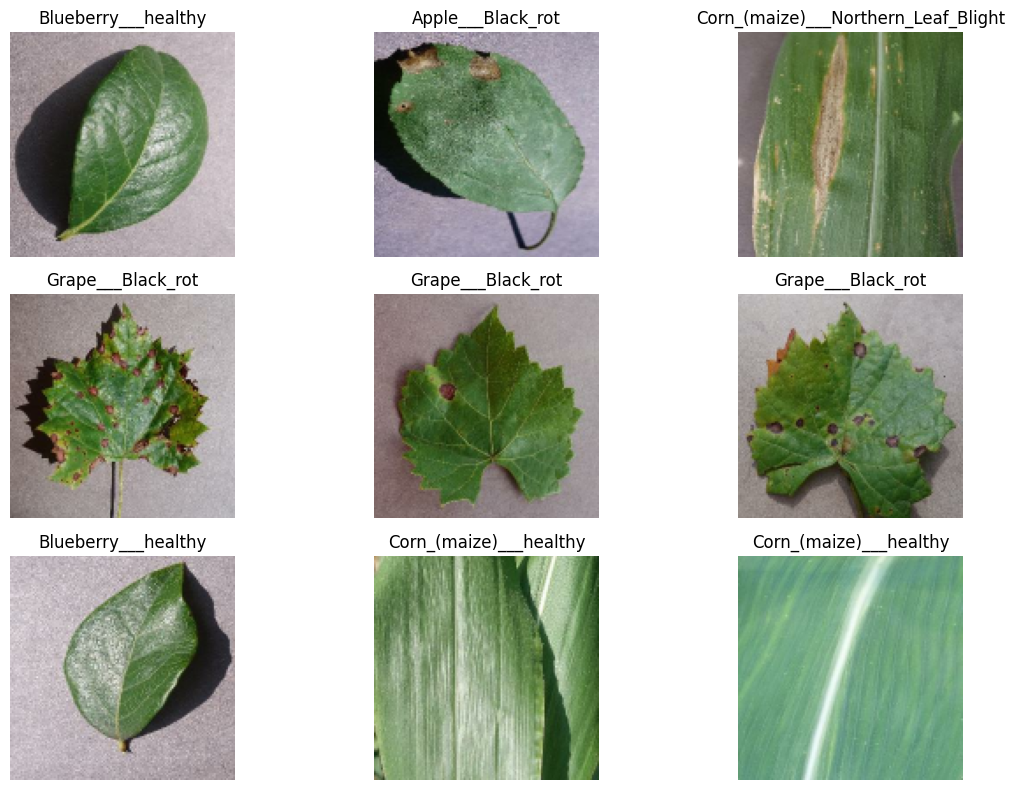

In [38]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())
        plt.title(index_to_class[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
# Import Keras layers and models from TensorFlow
from tensorflow.keras import layers, models

# Define a Sequential model to build a layer-by-layer CNN
model = models.Sequential([
    # Input layer specifying the input image dimensions (height, width, color channels)
    layers.Input(shape=(128, 128, 3)),

    # Light data augmentation to help reduce overfitting
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    # Convolutional block 1: Extracts 32 low-level features with batch normalization and pooling
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2: Extracts 64 mid-level features
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3: Extracts 128 high-level features
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification head: Flattens the feature maps into a 1D vector
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4), # Regularization to prevent overfitting

    # Output layer: One node per class outputting probability distributions via softmax
    layers.Dense(len(classes), activation="softmax")
])

# Compile the model using Adam optimizer and crossentropy loss for multi-class classification
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the detailed model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,934 (534.90 KB)

 Trainable params: 136,486 (533.15 KB)

 Non-trainable params: 448 (1.75 KB)

### Model Training Configuration & Execution

In this step, we prepare our training callbacks to optimize and save our baseline CNN model:
1. **`ModelCheckpoint`**: Saves only the best performing model based on validation loss.
2. **`EarlyStopping`**: Monitors validation loss and stops training early if the model ceases to improve, preventing overfitting.
3. **`ReduceLROnPlateau`**: Dynamically lowers the learning rate if validation loss stagnates, helping the model converge fine-tuned weights.

We then initiate the `.fit()` loop using our custom training and validation data streams.

In [40]:
MODEL_DIR = "/content/plant_disease_models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "baseline_cnn_best.keras"
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6888 - loss: 1.1183
Epoch 1: val_loss improved from None to 1.02198, saving model to /content/plant_disease_models/baseline_cnn_best.keras

Epoch 1: finished saving model to /content/plant_disease_models/baseline_cnn_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 64s 47ms/step - accuracy: 0.7370 - loss: 0.9390 - val_accuracy: 0.6985 - val_loss: 1.0220 - learning_rate: 0.0010
Epoch 2/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8512 - loss: 0.4837
Epoch 2: val_loss did not improve from 1.02198
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 77s 48ms/step - accuracy: 0.8637 - loss: 0.4354 - val_accuracy: 0.4655 - val_loss: 2.7428 - learning_rate: 0.0010
Epoch 3/20
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8950 - loss: 0.3222
Epoch 3: val_loss did not improve from 1.02198

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 58s 49ms/step - accuracy: 0.9047 

### Visualizing Training History

To evaluate how well our model learned over time and check for overfitting or underfitting, we plot the training and validation curves for both **Accuracy** and **Loss** over each completed epoch.

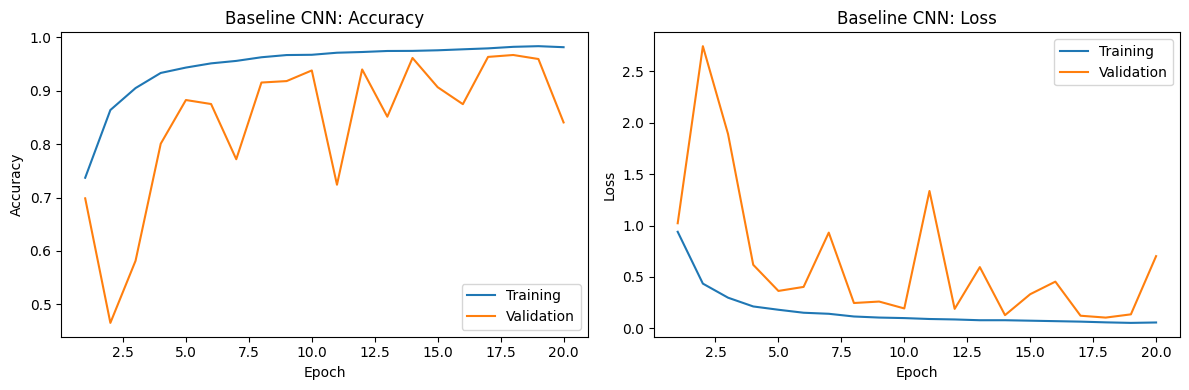

In [41]:
epochs_ran = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history.history["accuracy"], label="Training")
plt.plot(epochs_ran, history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN: Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history.history["loss"], label="Training")
plt.plot(epochs_ran, history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN: Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Evaluating Model on Test Dataset

We load the best baseline weights saved by our checkpoint and run a complete evaluation on our unseen **Test Split**. This provides crucial generalizability metrics, including Macro Precision, Recall, and F1-score.

Test

In [42]:
# Load the checkpoint with the best validation loss
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    average="macro",
    zero_division=0
)

print("\n===== BASELINE CNN: TEST RESULTS =====")
print(f"Test Loss:       {test_loss:.4f}")
print(f"Test Accuracy:   {test_accuracy:.4f}")
print(f"Macro Precision:{precision: .4f}")
print(f"Macro Recall:   {recall: .4f}")
print(f"Macro F1-score: {f1: .4f}")

255/255 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9711 - loss: 0.0925
255/255 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step

===== BASELINE CNN: TEST RESULTS =====
Test Loss:       0.0925
Test Accuracy:   0.9711
Macro Precision: 0.9675
Macro Recall:    0.9565
Macro F1-score:  0.9609


### Detailed Classification Report

We output a complete classification report to inspect individual precision, recall, and F1 scores for each of the 38 plant disease classes in our dataset.

In [43]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(classes)),
        target_names=[index_to_class[i] for i in range(len(classes))],
        digits=4,
        zero_division=0
    )
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9868    0.8065    0.8876        93
                                 Apple___Black_rot     0.8911    0.9783    0.9326        92
                          Apple___Cedar_apple_rust     1.0000    0.9250    0.9610        40
                                   Apple___healthy     0.9794    0.9520    0.9655       250
                               Blueberry___healthy     0.9779    0.9955    0.9866       222
          Cherry_(including_sour)___Powdery_mildew     1.0000    0.9658    0.9826       146
                 Cherry_(including_sour)___healthy     0.9583    0.9829    0.9705       117
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9000    0.9351    0.9172        77
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       179
               Corn_(maize)___Northern_Leaf_Blight     0.9722    0.9459    0.95

### Confusion Matrix Visualization

We calculate and plot a normalized confusion matrix to visually inspect which classes the model excels at distinguishing and where any slight classification confusions reside.

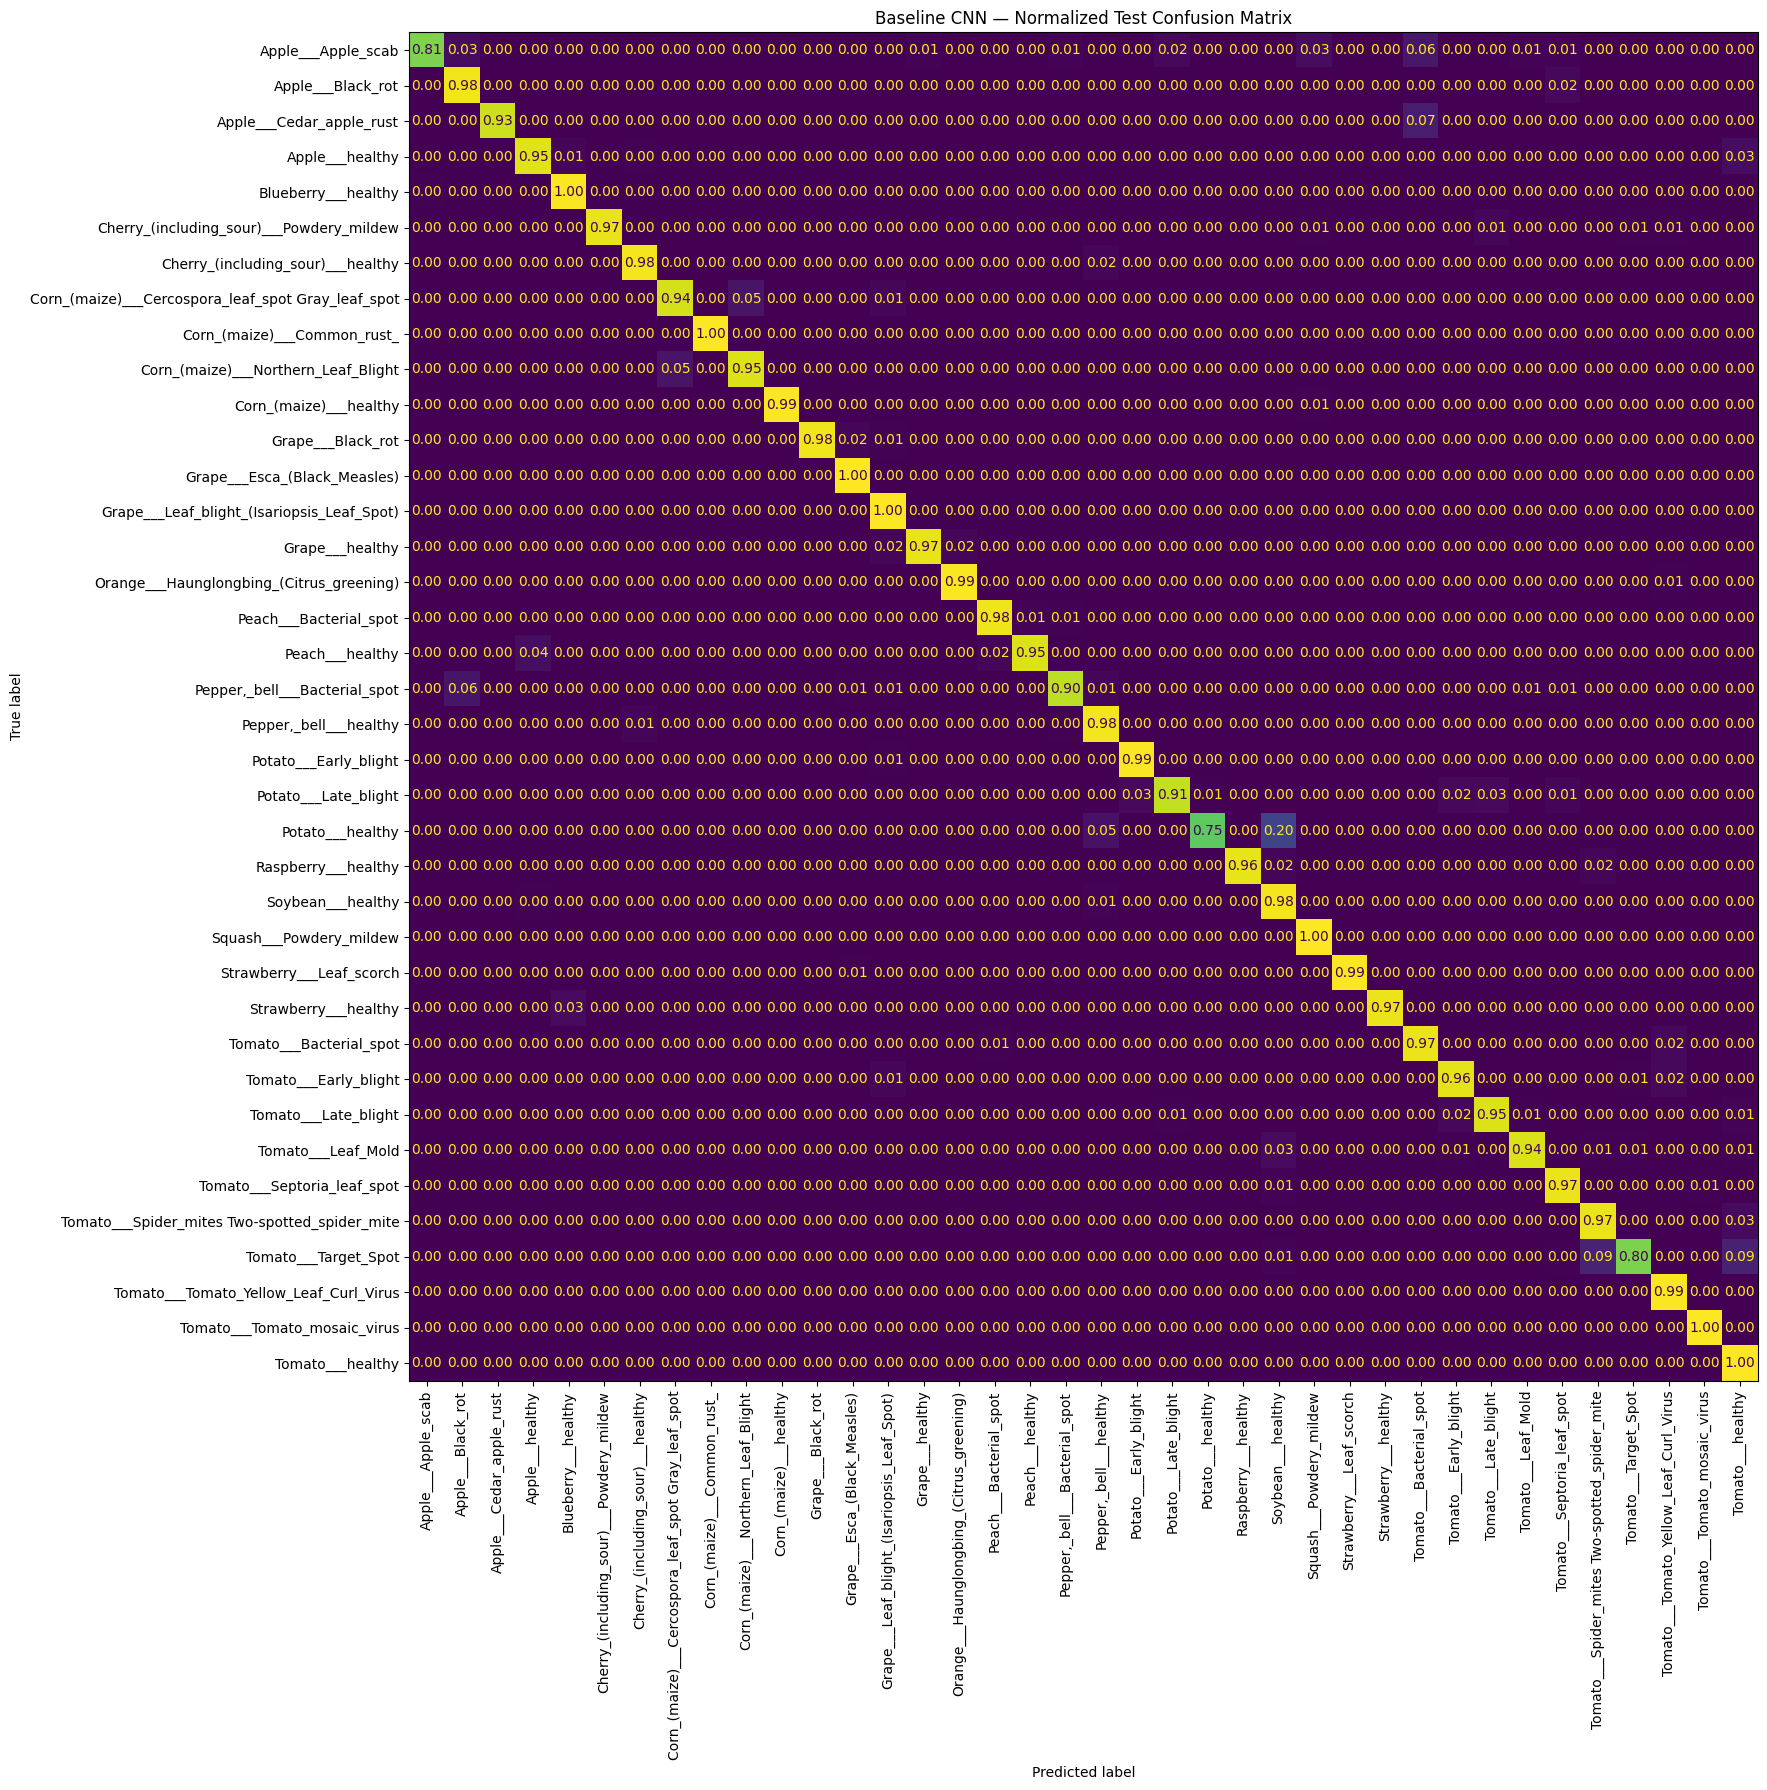

In [44]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    normalize="true"
)

fig, ax = plt.subplots(figsize=(20, 18))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[index_to_class[i] for i in range(len(classes))]
)

display.plot(
    ax=ax,
    xticks_rotation=90,
    values_format=".2f",
    colorbar=False
)

plt.title("Baseline CNN — Normalized Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Exporting Training Artifacts

We preserve our progress by exporting the training history, final classification metrics, and the class mappings as clean JSON files. Finally, we package these artifacts into a portable ZIP file.

In [45]:
import json
import shutil

# Save training history
history_path = os.path.join(MODEL_DIR, "baseline_training_history.json")

with open(history_path, "w") as f:
    json.dump(
        {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        },
        f,
        indent=4
    )

# Save test metrics
metrics = {
    "model": "Custom CNN trained from scratch",
    "dataset": "PlantVillage color images",
    "num_classes": len(classes),
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS,
    "epochs_completed": len(history.history["loss"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
    "seed": SEED
}

metrics_path = os.path.join(MODEL_DIR, "baseline_metrics.json")

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

# Save the class mapping
mapping_path = os.path.join(MODEL_DIR, "class_mapping.json")

with open(mapping_path, "w") as f:
    json.dump(
        {str(i): index_to_class[i] for i in range(len(classes))},
        f,
        indent=4
    )

# Package model artifacts
archive_path = shutil.make_archive(
    "/content/baseline_cnn_results",
    "zip",
    MODEL_DIR
)

print("Saved artifacts:")
print(BEST_MODEL_PATH)
print(history_path)
print(metrics_path)
print(mapping_path)
print(archive_path)

Saved artifacts:
/content/plant_disease_models/baseline_cnn_best.keras
/content/plant_disease_models/baseline_training_history.json
/content/plant_disease_models/baseline_metrics.json
/content/plant_disease_models/class_mapping.json
/content/baseline_cnn_results.zip


### External Image Prediction Demo

We set up a quick demonstration to predict a disease label from a newly uploaded external image file, printing the top 5 predicted classes with confidence levels.

In [46]:
from google.colab import files

uploaded = files.upload()

Saving healthy.jpg to healthy.jpg


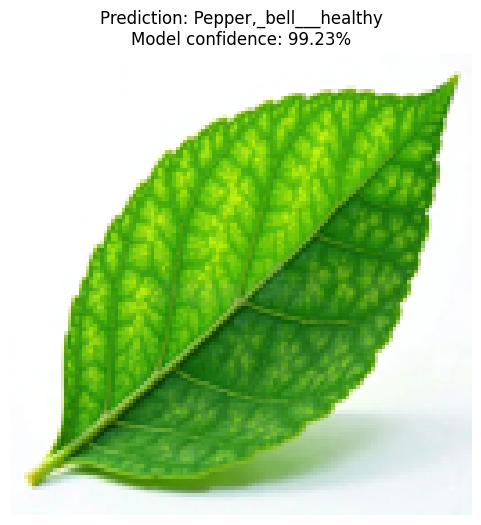

Predicted class: Pepper,_bell___healthy
Model confidence: 99.23%

Top 5 predictions:
Pepper,_bell___healthy: 99.23%
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.73%
Tomato___Late_blight: 0.01%
Blueberry___healthy: 0.01%
Cherry_(including_sour)___healthy: 0.01%


In [47]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

# Get the uploaded image filename
image_path = next(iter(uploaded.keys()))

# Load and preprocess the image
img = Image.open(image_path).convert("RGB")
img = img.resize((128, 128))

img_array = np.array(img, dtype=np.float32) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict using the trained baseline CNN
predictions = best_model.predict(img_array, verbose=0)[0]

# Find the predicted class
predicted_index = int(np.argmax(predictions))
predicted_class = index_to_class[predicted_index]
confidence = float(predictions[predicted_index]) * 100

# Display the image and result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Model confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

# Show the top 5 predictions
top_indices = np.argsort(predictions)[::-1][:5]

print("\nTop 5 predictions:")
for i in top_indices:
    print(f"{index_to_class[int(i)]}: {predictions[i] * 100:.2f}%")

#MobileNetV2 model

In [48]:
import os

print("Current working directory:", os.getcwd())
print("\nContents of /content:")

if os.path.exists("/content"):
    print(os.listdir("/content"))

print("\nContents of the current directory:")
print(os.listdir("."))

Current working directory: /content

Contents of /content:
['.config', 'healthy.jpg', 'plant_disease_models', 'baseline_cnn_results.zip', 'PlantVillage-Dataset', 'plant_disease_preprocessing', 'plant_disease_preprocessing.zip', 'sample_data']

Contents of the current directory:
['.config', 'healthy.jpg', 'plant_disease_models', 'baseline_cnn_results.zip', 'PlantVillage-Dataset', 'plant_disease_preprocessing', 'plant_disease_preprocessing.zip', 'sample_data']


In [49]:
import os

folders = [
    "/content/PlantVillage-Dataset",
    "/content/plant_disease_preprocessing",
    "/content/plant_disease_models"
]

for folder in folders:
    print(f"\n{'=' * 60}")
    print(f"Folder: {folder}")
    print("=" * 60)

    for root, dirs, files in os.walk(folder):
        depth = root.replace(folder, "").count(os.sep)

        if depth > 2:
            dirs[:] = []
            continue

        indent = "  " * depth
        print(f"{indent}{os.path.basename(root)}/")

        for filename in files[:10]:
            print(f"{indent}  {filename}")

        if len(files) > 10:
            print(f"{indent}  ... and {len(files) - 10} more files")


Folder: /content/PlantVillage-Dataset
PlantVillage-Dataset/
  generate_data_for_SVM.py
  generate_lmdb.sh
  leaf-map.json
  README.md
  README_HF.md
  CITATION.cff
  plant_village.py
  .gitignore
  generate_mapstring.py
  data_distribution_for_SVM/
    train_mapping.txt
    test_mapping.txt
    test/
    train/
  utils/
    image_processor.py
    image_processor.pyc
    __init__.py
    __init__.pyc
  generated_for_paper/
    img_5_segmented.eps
    img_19_grayscale.eps
    img_5_grayscale.eps
    img_10_color.eps
    img_18_segmented.eps
    img_8_color.eps
    img_17_color.eps
    img_14_color.eps
    img_16_segmented.eps
    img_0_color.eps
    ... and 52 more files
  scripts/
    generate_data_color-80-20.sh
    generate_data_grayscale-50-50.sh
    generate_data_grayscale-60-40.sh
    generate_data_color-40-60.sh
    generate_data_segmented-80-20.sh
    upload_to_hf.py
    generate_data_segmented-60-40.sh
    run_all.sh
    generate_data_color-20-80.sh
    generate_data_grayscale-2

In [50]:
import json
import os
import pandas as pd

PREPROCESS_DIR = "/content/plant_disease_preprocessing"
MODEL_DIR = "/content/plant_disease_models"

# Inspect experiment configuration
config_path = os.path.join(
    PREPROCESS_DIR,
    "experiment_config.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print("EXPERIMENT CONFIGURATION")
print(json.dumps(config, indent=2))

# Inspect split manifests
for filename in [
    "final_split_manifest.csv",
    "train.csv",
    "validation.csv",
    "test.csv",
    "image_inventory.csv"
]:
    path = os.path.join(PREPROCESS_DIR, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print(f"\n{'=' * 60}")
        print(f"{filename}: {df.shape}")
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

EXPERIMENT CONFIGURATION
{
  "dataset": "PlantVillage raw/color",
  "number_of_classes": 38,
  "original_images": 54305,
  "exact_duplicate_copies_removed": 21,
  "images_after_deduplication": 54284,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  },
  "random_state": 42,
  "grouping_method": "Verified class-specific leaf IDs where available; SHA-256 image groups otherwise",
  "fully_leaf_grouped_across_all_classes": false
}

final_split_manifest.csv: (54284, 9)
Columns: ['image_path', 'filename', 'class_label', 'extension', 'sha256', 'leaf_id', 'metadata_status', 'split_group', 'split']
                                                                                                          image_path                                                  filename        class_label extension                                                           sha256 leaf_id    metadata_status                    split_group      split
/content/PlantVillage-Dataset/raw/

In [51]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [52]:
import os
import json
import pandas as pd
import numpy as np

PREPROCESS_DIR = "/content/plant_disease_preprocessing"
MODEL_DIR = "/content/plant_disease_models"

train_df = pd.read_csv(
    f"{PREPROCESS_DIR}/train.csv"
)
val_df = pd.read_csv(
    f"{PREPROCESS_DIR}/validation.csv"
)
test_df = pd.read_csv(
    f"{PREPROCESS_DIR}/test.csv"
)

# Use the same class mapping as the baseline CNN
with open(f"{MODEL_DIR}/class_mapping.json", "r") as f:
    class_mapping = json.load(f)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))
print("Number of classes:", len(class_mapping))

# Check class distribution
print("\nTraining images per class:")
print(train_df["class_label"].value_counts().sort_index())

# Check image paths
for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    missing = (~df["image_path"].map(os.path.isfile)).sum()
    print(f"Missing {name} images:", missing)

# Check split overlap by exact image hash
train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

print("\nExact-hash overlap:")
print("Train vs validation:", len(train_hashes & val_hashes))
print("Train vs test:", len(train_hashes & test_hashes))
print("Validation vs test:", len(val_hashes & test_hashes))

Training images: 37991
Validation images: 8135
Test images: 8158
Total images: 54284
Number of classes: 38

Training images per class:
class_label
Apple___Apple_scab                                     453
Apple___Black_rot                                      435
Apple___Cedar_apple_rust                               191
Apple___healthy                                       1139
Blueberry___healthy                                   1080
Cherry_(including_sour)___Powdery_mildew               755
Cherry_(including_sour)___healthy                      599
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     359
Corn_(maize)___Common_rust_                            834
Corn_(maize)___Northern_Leaf_Blight                    689
Corn_(maize)___healthy                                 813
Grape___Black_rot                                      824
Grape___Esca_(Black_Measles)                           967
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)             752
Grape___healthy            

In [53]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Convert the loaded baseline class mapping (where keys are string indices and values are class names)
# into a sorted list of class names based on their integer index.
try:
    # class_mapping keys are strings like "0", "1", etc. We convert them to integers.
    sorted_mapping = sorted(
        [(int(idx), name) for idx, name in class_mapping.items()],
        key=lambda item: item[0]
    )
    class_names = [name for _, name in sorted_mapping]
except Exception as e:
    raise ValueError(
        f"Failed to parse class_mapping.json: {e}. Please inspect class_mapping structure."
    )

class_to_index = {
    name: idx for idx, name in enumerate(class_names)
}

assert len(class_names) == 38
assert set(train_df["class_label"]) == set(class_names)

def make_dataset(df, training=False):
    paths = df["image_path"].astype(str).to_numpy()
    labels = df["class_label"].map(class_to_index).to_numpy(
        dtype=np.int32
    )

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)
        image = preprocess_input(image)

        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(
            buffer_size=4096,
            seed=42,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("MobileNetV2 datasets are ready.")

MobileNetV2 datasets are ready.


In [54]:
from tensorflow.keras import layers, models

# Load MobileNetV2 pre-trained on the ImageNet dataset as the base feature extractor
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False, # Exclude the top classification layers so we can train our own head
    input_shape=(224, 224, 3)
)

# Freeze the base model weights to preserve the learned ImageNet features
base_model.trainable = False

# Create input layer matching the required MobileNetV2 dimensions
inputs = layers.Input(shape=(224, 224, 3))

# Pass inputs through the pre-trained feature extractor
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x) # Flatten features into a 1D vector
x = layers.Dropout(0.3)(x) # Regularization dropout layer

# Dense classifier matching our 38 plant disease classes
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

# Instantiate the Keras model with inputs and outputs
mobilenet_model = models.Model(inputs, outputs)

# Compile using standard crossentropy and a default classification optimizer
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [55]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/plant_disease_models/mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

mobilenet_model.save(
    "/content/plant_disease_models/mobilenetv2_plant_disease.keras"
)

Epoch 1/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 115s 72ms/step - accuracy: 0.8601 - loss: 0.4969 - val_accuracy: 0.7868 - val_loss: 0.6652
Epoch 2/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 64s 51ms/step - accuracy: 0.9367 - loss: 0.2006 - val_accuracy: 0.8836 - val_loss: 0.3605
Epoch 3/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 61s 48ms/step - accuracy: 0.9514 - loss: 0.1510 - val_accuracy: 0.9067 - val_loss: 0.2829
Epoch 4/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 63s 49ms/step - accuracy: 0.9572 - loss: 0.1306 - val_accuracy: 0.9117 - val_loss: 0.2822
Epoch 5/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 63s 49ms/step - accuracy: 0.9606 - loss: 0.1185 - val_accuracy: 0.9235 - val_loss: 0.2397
Epoch 6/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 94s 60ms/step - accuracy: 0.9631 - loss: 0.1089 - val_accuracy: 0.9216 - val_loss: 0.2404
Epoch 7/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 61s 47ms/step - accuracy: 0.9640 - loss: 0.1058 - val_accuracy: 0.9262 - val_loss: 0.2407
Epoch 8/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 62s 49ms/step - accuracy: 0.9647 

In [56]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = mobilenet_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("===== MOBILENETV2 TEST RESULTS =====")
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("Confusion matrix shape:", cm.shape)

255/255 ━━━━━━━━━━━━━━━━━━━━ 33s 112ms/step
===== MOBILENETV2 TEST RESULTS =====
Test accuracy: 0.9441

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9722    0.7527    0.8485        93
                                 Apple___Black_rot     1.0000    0.9348    0.9663        92
                          Apple___Cedar_apple_rust     1.0000    0.9250    0.9610        40
                                   Apple___healthy     0.9875    0.9480    0.9673       250
                               Blueberry___healthy     1.0000    0.9685    0.9840       222
          Cherry_(including_sour)___Powdery_mildew     0.9924    0.8904    0.9386       146
                 Cherry_(including_sour)___healthy     1.0000    0.9829    0.9914       117
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8333    0.9091    0.8696        77
                       Corn_(maize)___Common

===== MOBILENETV2: EXTERNAL IMAGE PREDICTION =====
Predicted class: Tomato___Leaf_Mold
Model confidence: 47.32%

Top 5 predictions:
Tomato___Leaf_Mold: 47.32%
Orange___Haunglongbing_(Citrus_greening): 23.67%
Pepper,_bell___Bacterial_spot: 19.57%
Strawberry___healthy: 6.16%
Blueberry___healthy: 0.99%


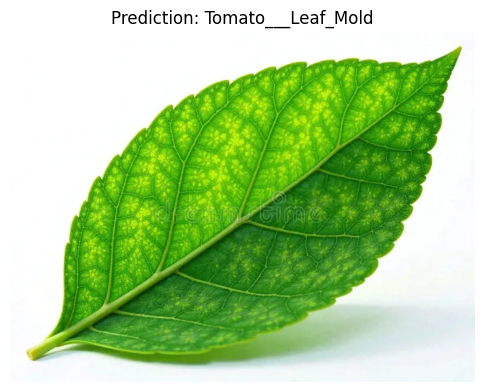

In [58]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMAGE_PATH = "/content/healthy.jpg"

# Load and preprocess the external image
img = load_img(IMAGE_PATH, target_size=(224, 224))
img_array = img_to_array(img)

img_batch = np.expand_dims(img_array, axis=0)
img_batch = preprocess_input(img_batch)

# Predict
predictions = mobilenet_model.predict(img_batch, verbose=0)[0]

top5_indices = np.argsort(predictions)[-5:][::-1]

print("===== MOBILENETV2: EXTERNAL IMAGE PREDICTION =====")
print("Predicted class:", class_names[top5_indices[0]])
print(f"Model confidence: {predictions[top5_indices[0]] * 100:.2f}%")

print("\nTop 5 predictions:")

for idx in top5_indices:
    print(f"{class_names[idx]}: {predictions[idx] * 100:.2f}%")

plt.figure(figsize=(6, 6))
plt.imshow(load_img(IMAGE_PATH))
plt.axis("off")
plt.title(f"Prediction: {class_names[top5_indices[0]]}")
plt.show()

In [ ]:
import shutil
import os

source_path = "/content/plant_disease_models/baseline_cnn_best.keras"
target_path = "/content/crop_disease_cnn.keras"

if os.path.exists(source_path):
    shutil.copy(source_path, target_path)
    print(f"Successfully saved the Baseline CNN model to: {target_path}")
else:
    print(f"Error: Best model checkpoint not found at {source_path}")

In [ ]:
import os

print(os.path.exists("crop_disease_cnn.keras"))

In [ ]:
import json

# Since class_names is already defined in the kernel from our class mapping,
# we can directly write it to class_names.json.
with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Total classes:", len(class_names))
print(class_names)

In [ ]:
from google.colab import files

files.download("crop_disease_cnn.keras")
files.download("class_names.json")

In [ ]:
import os

print("=== Checking /content directory structure ===")
for root, dirs, files in os.walk("/content"):
    # Avoid deep-scanning dataset raw images to keep output clean
    if "PlantVillage-Dataset" in root and root != "/content/PlantVillage-Dataset":
        continue
    print(f"{root}/")
    for f in files[:10]:
        print(f"  {f}")
    if len(files) > 10:
        print(f"  ... and {len(files) - 10} more files")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')